<center>
    <h2 style="font-size: 48px; margin-bottom: 5px;"><b>PROJECT QUIZ </b></h2>
</center>

<center>
    <h3 style="font-size: 36px; margin-top: 0px; margin-bottom: 5px;">- DELIVERABLE  -</h3>
</center>

<br> <br>

<center> <img src="https://www.alsacetech.org/wp-content/uploads/2017/05/cesi_CMJN-e1673249263164.png" alt="logo" width="200"></center>

<br> <br>

## Group 2 :
- ACACHA Elie
- PALE Kharice
- DEMIRHINDI Sude
- MERKICHE Isak
- LOUACHE Manyl

<br> <br>


# **CONTEXT**

Since the 1990s reducing energy consumption and greenhouse gas emissions have become a global objective. Transportation and delivery services contribute to these emissions improving delivery routes can help reduce the environmental impact. In this context ADEME (the French Environment and Energy Management Agency) promotes the development of mobility solutions for people and goods. CesiCDP wants to respond to this initiative by developing a method for managing delivery routes. Optimizing delivery routes can help companies reduce fuel consumption, travel time and operating costs.

# **PROBLEM**

Here we want to develop a method or a way to manage delivering route. Our main goal is to optimize those routes to reduces the company fuel comsumption, travel time and operating costs.The main problem of this project is to optimize the delivery routes on a road network. The objective is to find the efficient delivery routes for a convoy of delivering trucks that go to different customers and return to the starting point while minimizing travel time and respecting each delivery time window. This problem is known as the Capacitated Vehicle Routing Problem with Time Window (CVRPTW). Each truck has a capacity, and every customer must receive their deliveries in their time window and at each customer we must verify a certain service time duration. The algorithm must decide which customers each truck should visit and in which order. The main challenges are the number of possible deliveries routes the capacity limits of the trucks and the differences in traffic conditions and the differents time constraints. As the number of customers increases finding the best delivery routes becomes more difficult. This problem will the requires efficient algorithms.

# **OVERALL OBJECTIVES**
The main objective is to develop an algorithm of finding efficient delivery routes for realistic situations that involve several thousand customers.
The project has specific objectives:
- Model the delivery problem mathematically.
-	Develop an algorithm in Python to calculate delivery routes.
-	Respect the capacity limits of the trucks.
-	Minimize the travel time.
-	Evaluate the algorithms performance in terms of computation time and solution quality.
-	Test the algorithm on instances and compare its results with known reference solutions.
-	Time windows: each customer must be served during a specific period

# **Concrete Examples and Use Cases**

A typical example is a delivery company that must deliver packages to 100 customers using trucks. Each truck has a carrying capacity and every customer must be visited. A simple solution would be to visit customers in the order in which their addresses are received. However, this could create delivery routes, unnecessary travel and higher fuel consumption. With delivery route optimization the algorithm assigns customers to trucks and determines the order of visits to reduce the total travel time while respecting vehicle capacities. Another example is supermarket delivery service. Some customers may only be available to receive their orders between 10 a.m. And noon. In the version the algorithm must organize the delivery routes so that deliveries take place within these time windows. These applications show how delivery route optimization can improve delivery efficiency, reduce operating costs and support sustainable transportation.


# **Modeling and solution methods**


## Data Formalization

### 1. Benchmark instances and file formats

We test our methods on the **Solomon benchmark** (100 customers) and its extension by **Gehring & Homberger** (200 to 1000 customers), the standard benchmarks for the CVRPTW. All files come from the [PyVRP/VRPLIB](https://github.com/PyVRP/VRPLIB) repository. We read them with the Python package `vrplib`, which returns every instance as the same Python dictionary, whatever its file format.

The instances come in two file formats.

#### 1.1 Solomon format (`.txt`)

This is the original format of the benchmark. The file has a short header with the fleet, followed by a table with one row per node. Row `0` is the depot.

```
C101

VEHICLE
NUMBER     CAPACITY
  25         200

CUSTOMER
CUST NO.  XCOORD.   YCOORD.    DEMAND   READY TIME  DUE DATE   SERVICE   TIME
    0      40         50          0          0       1236          0
    1      45         68         10        912        967         90
    2      45         70         30        825        870         90
```

| Column | Meaning |
|---|---|
| `NUMBER` | number of available vehicles |
| `CAPACITY` | capacity of each vehicle (all vehicles are identical) |
| `CUST NO.` | node index (0 = depot) |
| `XCOORD.`, `YCOORD.` | coordinates of the node |
| `DEMAND` | quantity to deliver to the customer |
| `READY TIME`, `DUE DATE` | time window: earliest and latest start of service |
| `SERVICE TIME` | duration of the service at the customer |

The file contains **no distances**: `vrplib` computes them from the coordinates as real-valued Euclidean distances. It is read with `vrplib.read_instance(path, instance_format="solomon")`.

#### 1.2 VRPLIB / LKH-3 format (`.vrptw`)

This format follows the TSPLIB convention: a header of `KEY : value` lines, then one section per type of data.

```
NAME : C102
TYPE : CVRPTW
DIMENSION : 101          <- number of nodes (depot + 100 customers)
VEHICLES : 10
CAPACITY : 200
SERVICE_TIME : 90        <- one value for every customer
EDGE_WEIGHT_TYPE : EXACT_2D
NODE_COORD_SECTION       <- "node x y"
1 40 50
2 45 68
...
DEMAND_SECTION           <- "node demand"
TIME_WINDOW_SECTION      <- "node ready due"
DEPOT_SECTION            <- depot index, ended by -1
1
-1
EOF
```

Differences with the Solomon format:

- Nodes are numbered from **1** in the file; `vrplib` shifts them so that the depot is node **0**, as in the Solomon files.
- The service time is a **single value** for all customers. The depot has no service, so we set $s_0 = 0$.
- `EDGE_WEIGHT_TYPE` tells how distances are computed. With `EXACT_2D` and `EUC_2D`, `vrplib` returns the real Euclidean distance; with `FLOOR_2D`, it rounds the distance down to an integer. All the instances we use give real distances.
- In the LKH-3 files, the fleet is much tighter. In the file name `C102.100.10`, 100 is the number of customers and 10 the number of vehicles. Here $|K| = \lceil \sum_i d_i / Q \rceil$, so no vehicle is spare. The `.vrp` file of RC101 uses the same format but keeps the original Solomon fleet of 25 vehicles.

It is read with `vrplib.read_instance(path)`.

#### 1.3 Data actually used in our computations

Some fields of the files describe the instance but do not take part in the computations (`NAME`, `TYPE`, `COMMENT`, `DIMENSION`, `DEPOT_SECTION`, `SCALE`). The table below lists the fields that do take part, and how `vrplib` gives them to us.

| Data | Solomon `.txt` | `.vrptw` | `vrplib` key | Python shape | Symbol |
|---|---|---|---|---|---|
| Number of vehicles | `NUMBER` | `VEHICLES` | `vehicles` | integer | $\lvert K\rvert$ |
| Vehicle capacity | `CAPACITY` | `CAPACITY` | `capacity` | integer | $Q$ |
| Coordinates | `XCOORD.`, `YCOORD.` | `NODE_COORD_SECTION` | `node_coord` | $(n+1)\times 2$ | $(x_i, y_i)$ |
| Demands | `DEMAND` | `DEMAND_SECTION` | `demand` | $n+1$ | $d_i$ |
| Time windows | `READY TIME`, `DUE DATE` | `TIME_WINDOW_SECTION` | `time_window` | $(n+1)\times 2$ | $[b_i, e_i]$ |
| Service times | `SERVICE TIME` | `SERVICE_TIME` | `service_time` | $n+1$ or scalar | $s_i$ |
| Travel times | computed | computed | `edge_weight` | $(n+1)\times(n+1)$ | $\tau_{ij}$ |

The depot row gives $d_0 = 0$, and its time window $[b_0, e_0]$ is the working day: vehicles leave the depot at $b_0$ at the earliest and must be back by $e_0$.

#### 1.4 Instances used in this project

| Instance | Format | Customers $n$ | Vehicles $\lvert K\rvert$ | $Q$ | Total demand | Min. vehicles $\lceil \sum d_i / Q\rceil$ | $[b_0, e_0]$ | Used for |
|---|---|---|---|---|---|---|---|---|
| C101 | Solomon `.txt` | 100 | 25 | 200 | 1810 | 10 | [0, 1236] | ILP and ALNS, reference solution `C101.sol` |
| RC101 (first 20 customers) | `.vrp` (EUC_2D) | 20 | 25 | 200 | 430 | 3 | [0, 240] | ILP, tighter time windows |
| C102.100.10 | `.vrptw` (EXACT_2D) | 100 | 10 | 200 | 1810 | 10 | [0, 1236] | ALNS, wider time windows |
| C1_2_1 | Homberger `.txt` | 200 | 50 | 200 | 3530 | 18 | [0, 1351] | ALNS, reference solution `C1_2_1.sol` |

For the ILP, an instance can be cut down to its depot and its **first $n$ customers**, to study how the solving time grows with $n$.

For the reference instances, the `.sol` files give the best known solution: one line per route, then its cost. The published cost of C101 (827.3) uses distances truncated to one decimal, the original Solomon convention. With exact distances, the same routes cost **828.94**, so we always recompute the reference cost with our own distances before we compare.

### 2. Graph model

An instance is modelled as a **complete directed graph**

$$
G = (V, A), \qquad V = \{0\} \cup N, \qquad N = \{1, \dots, n\}, \qquad A = \{(i,j) \in V \times V : i \neq j\}
$$

- Node $0$ is the depot, where every route starts and ends.
- $N$ is the set of the $n$ customers.
- An arc $(i,j)$ is a direct trip from $i$ to $j$. Every pair of nodes is linked, so $\lvert A\rvert = n(n+1)$, which gives 650 arcs for 25 customers and 10 100 for 100 customers.

**Weight of an arc.** Following the Solomon convention, one unit of distance takes one unit of time, so the travel time is the Euclidean distance between the two nodes:

$$
\tau_{ij} = c_{ij} = \sqrt{(x_i - x_j)^2 + (y_i - y_j)^2}
$$

The travel time $\tau_{ij}$ is also the cost $c_{ij}$ that we minimise. The matrix is symmetric ($\tau_{ij} = \tau_{ji}$) and satisfies the triangle inequality, so going through an extra customer never shortens a trip.

**Weight of a node.** Each customer $i \in N$ carries a demand $d_i$, a time window $[b_i, e_i]$ and a service time $s_i$.

**Real-valued times.** Both methods use the exact, real Euclidean distances. The ILP uses the matrix `edge_weight` from `vrplib`, and the ALNS recomputes the same distances from the coordinates. In the ILP, the service start times are continuous variables, so travel times do not need to be integers.

### 3. Fleet

The fleet $K$ is **homogeneous**: every vehicle has the same capacity $Q = 200$ in all our instances. $\lvert K\rvert$ is an **upper bound**: a solution may use fewer vehicles. Each vehicle used performs a single route $R_k = (0, i_1, \dots, i_r, 0)$, and its load must not exceed the capacity:

$$
\sum_{i \in R_k} d_i \le Q
$$

Since demands cannot be split, at least $\lceil \sum_{i \in N} d_i / Q \rceil$ vehicles are needed. For C101 this gives 10 vehicles, and the best known solution indeed uses 10 routes out of the 25 available.

### 4. Time along a route

A vehicle leaves the depot at $T_0 = b_0$. When it goes from $i$ to $j$, it arrives at $a_j = T_i + s_i + \tau_{ij}$. If it arrives before the window opens, it waits, so service starts at

$$
T_j = \max(b_j, a_j)
$$

The route is feasible if $T_j \le e_j$ for every customer visited and if the vehicle is back at the depot by $e_0$. In C101 every customer needs $s_i = 90$ time units of service, which is long compared with the travel times (for example $\tau_{01} \approx 18.7$). Time windows, more than distances, therefore drive the number of customers a vehicle can serve.


## Complexity Proof
## 1. Complexity classification

The **Capacitated Vehicle Routing Problem with Time Windows (CVRPTW)** is an NP-hard combinatorial problem.

The objective is to minimize the total routing time cost while satisfying vehicle capacity constraints and customer time-window constraints. Every customer must be visited exactly once, and every vehicle route must start and end at the depot.

To establish its complexity, we consider the associated decision problem.

**CVRPTW-Decision**: Given a CVRPTW instance and a cost bound $B$, does there exist a set of feasible vehicle routes whose total cost is at most $B$ ?
The complexity classification is:
- Decision version: **NP-complete**.
- Optimization version: **NP-hard**.

We establish this classification by proving that the decision version belongs to NP and is NP-hard through a polynomial-time reduction from the decision version of the traveling salesman problem (TSP).

## 2. Proof that CVRPTW-Decision belongs to NP

To prove that CVRPTW-Decision belongs to NP, we must show that a proposed solution can be verified in polynomial time.

### Certificate

A certificate is a set of vehicle routes representing a solution structure for our problem:

$$
S=(R_1,R_2,\ldots,R_m)
\qquad m\leq |K|
$$

where each route starts and ends at the depot and gives the sequence of customers visited by its vehicle. The certificate has polynomial size: it lists each customer once and the depot twice per route, so at most $n + 2\lvert K\rvert$ nodes.

### Verification

Given a certificate $S$, we must verify the following conditions based on the problem constraints.

1. **Customer coverage:** Every customer is visited exactly once.
2. **Route structure:** Every vehicle route starts and ends at the depot, and the number of routes does not exceed the available fleet size.
3. **Capacity constraints:** For each route $R_k$, the total demand of its customers does not exceed the vehicle capacity $Q$.
4. **Time-window constraints:** Each customer is served within its time window.
5. **Cost bound:** the total cost of all routes is at most $B$.
6. **Depot return deadline:** every route returns by time $e_0$.

For time-window verification, let customer $i$ have a time window $[b_i,e_i]$, service duration $s_i$, and let $\tau_{ij}$ be the travel time from customer $i$ to customer $j$.

The earliest feasible service-start time at customer $j$, following customer $i$, is:

$$
T_j=\max\left(b_j,T_i+s_i+\tau_{ij}\right)
$$

We then verify that $T_j\leq e_j$.
If this inequality fails for any customer, the proposed route is infeasible. Otherwise, we continue along the route, and finally check that the vehicle is back at the depot by $e_0$.

Each node of the certificate is processed once, in constant time: one look-up in the travel-time matrix, one update of the load and of the time, and one mark in a boolean array to detect a customer visited twice or never. The whole verification therefore runs in $O(n + \lvert K\rvert)$, which is polynomial in the input size.

Therefore,

$$
\boxed{\text{CVRPTW-Decision}\in NP}
$$

## 3. Proof that CVRPTW-Decision is NP-Hard

We are going to prove this by reducing the decision problem of the travelling salesman problem to CVRPTW-Decision.

### 3.1. Source problem: TSP-Decision

An instance of TSP-Decision consists of a complete weighted graph $G=(V,E)$
a depot vertex $r\in V$, edge costs $c_{ij}$ and a cost bound $B$.

The question is whether there exists a Hamiltonian cycle that starts at $r$, visits every vertex exactly once, returns to $r$, and has total time cost at most $B$.

TSP-Decision is NP-complete (Karp, 1972, through the Hamiltonian cycle problem).

### 3.2. Polynomial-time transformation

Let $m=|V|$. Given an arbitrary TSP-Decision instance, construct a CVRPTW instance as follows:

- **Depot:** use the TSP vertex $r$ as the depot, relabeled $0$.
- **Customers:** each vertex in $V\setminus\{r\}$ becomes a customer.
- **Fleet size:** provide exactly **one** vehicle.
- **Demand:** set $d_i=1$ for every customer.
- **Vehicle capacity:** set $Q=m-1$, sufficient to serve all customers.
- **Travel costs:** preserve every TSP arc cost, $c'_{ij}=c_{ij}$.
- **Travel times:** set $\tau'_{ij}=c_{ij}$ so that total travel time equals TSP tour cost.
- **Service times:** set $s_i=0$ for every customer and for the depot.
- **Time windows:** assign $[0,H]$ to every customer and to the depot, with

$$
H=mC_{\max}+1,\qquad C_{\max}=\max_{(i,j)\in E}c_{ij}.
$$

A Hamiltonian cycle has exactly $m$ arcs, each costing at most $C_{\max}$; therefore its total travel time is at most $mC_{\max}<H$. These wide windows do not remove any TSP tour.

- **Objective bound:** keep the same bound $B$.

The constructed instance contains a polynomial number of nodes and arcs. Because the integer $H$ has polynomially many bits relative to the input encoding, this transformation runs in polynomial time.

### 3.3. Proof of reduction

We prove equivalence in both directions.

**Direction 1: TSP-Decision has a solution $\Rightarrow$ CVRPTW-Decision has a solution.**

Suppose that the TSP instance has a Hamiltonian cycle of total cost at most $B$. Use this cycle as the route of the single vehicle. Every customer is visited exactly once; capacity $Q=m-1$ allows all unit demands; service durations are zero; and the time horizon is large enough to accommodate the complete route. Since travel times equal the original TSP costs, the total CVRPTW travel time is also at most $B$. Therefore, the constructed CVRPTW instance is a **yes-instance**.

**Direction 2: CVRPTW-Decision has a solution $\Rightarrow$ TSP-Decision has a solution.**

Suppose that the constructed CVRPTW instance admits a feasible solution of total travel time at most $B$. There is only one vehicle, and the routing rules require it to start from the depot, serve every customer exactly once and return to the depot. Consequently, its route is a Hamiltonian cycle through all vertices of the original TSP graph. Because the travel times were copied from TSP arc costs, the original cycle has cost at most $B$. Therefore, the TSP instance is also a **yes-instance**.

We have established:

$$
\boxed{\text{TSP-Decision is a yes-instance}\iff\text{CVRPTW-Decision is a yes-instance}.}
$$

Hence:

$$
\text{TSP-Decision}\leq_p\text{CVRPTW-Decision}.
$$

Since TSP-Decision is NP-complete, CVRPTW-Decision is NP-hard. Combined with membership in NP, this yields:

$$
\boxed{\text{CVRPTW-Decision is NP-complete}.}
$$

Consequently, the **optimization version of the general CVRPTW is NP-hard**.


## Mathematical Modeling (ILP)

We use the compact **two-index formulation**. Since all vehicles are identical, one set of arc variables is enough for the whole fleet: we do not need to know *which* vehicle drives an arc, only *whether* an arc is used. Loads and times are tracked with Miller–Tucker–Zemlin (MTZ) style constraints, linearised with big-M.

### 1. Data

We use the notation of the Data Formalization: the graph $G = (V, A)$ with $V = \{0\} \cup N$, the travel times $\tau_{ij} = c_{ij}$, the demands $d_i$, the service times $s_i$ (with $s_0 = 0$), the time windows $[b_i, e_i]$, the depot window $[b_0, e_0]$, the capacity $Q$ and the fleet size $\lvert K\rvert$.

### 2. Variables

| Variable | Domain | Meaning |
|---|---|---|
| $x_{ij}$ | $\{0,1\}$, $(i,j) \in A$ | $=1$ if a vehicle travels directly from $i$ to $j$ |
| $T_i$ | $\mathbb{R}_{\ge 0}$, $i \in V$ | start of service at node $i$ ($T_0$ = departure time from the depot) |
| $u_i$ | $\mathbb{R}$, $i \in N$ | load of the vehicle just after it serves customer $i$ |

### 3. Objective

$$
\min \sum_{(i,j) \in A} c_{ij}\, x_{ij}
$$

### 4. Constraints

$$
\begin{aligned}
&(1)\ \textstyle\sum_{j : (i,j) \in A} x_{ij} = 1 && \forall i \in N && \text{each customer is left exactly once}\\
&(2)\ \textstyle\sum_{j : (j,i) \in A} x_{ji} = 1 && \forall i \in N && \text{each customer is reached exactly once}\\
&(3)\ \textstyle\sum_{j \in N} x_{0j} \le \lvert K\rvert && && \text{fleet size}\\
&(3')\ \textstyle\sum_{j \in N} x_{0j} \ge \left\lceil \sum_{i \in N} d_i / Q \right\rceil && && \text{valid inequality}\\
&(4)\ u_j \ge u_i + d_j - Q\,(1 - x_{ij}) && \forall (i,j) \in A,\ i, j \in N && \text{load propagation}\\
&(5)\ d_i \le u_i \le Q && \forall i \in N && \text{capacity}\\
&(6)\ T_j \ge T_i + s_i + \tau_{ij} - M_{ij}\,(1 - x_{ij}) && \forall (i,j) \in A,\ j \in N && \text{schedule consistency}\\
&(7)\ T_i + s_i + \tau_{i0} \le e_0 + M_{i0}\,(1 - x_{i0}) && \forall i \in N && \text{return to the depot before closing}\\
&(8)\ b_i \le T_i \le e_i && \forall i \in V && \text{time windows}
\end{aligned}
$$

Constraints (1) and (2) also balance the depot: $n$ arcs leave the customers and $n$ arcs reach them, so as many vehicles come back to the depot as leave it. All vehicles share the departure time $T_0$. This loses nothing: waiting is allowed, so leaving at $b_0$ is always possible.

### 5. Choice of the big-M values

When $x_{ij} = 1$, the term $M(1 - x_{ij})$ is zero and the constraint applies. When $x_{ij} = 0$, the constraint must hold for **every** feasible value of the variables, so that it is inactive. This gives the **smallest valid M**:

- **Time (6):** we need $T_i + s_i + \tau_{ij} - M_{ij} \le T_j$ for all $T_i \le e_i$ and $T_j \ge b_j$, so
$$M_{ij} = \max(0,\ e_i + s_i + \tau_{ij} - b_j).$$
- **Return (7):** in the same way, $M_{i0} = \max(0,\ e_i + s_i + \tau_{i0} - e_0)$.
- **Load (4):** we need $u_i + d_j - M \le u_j$ for all $u_i \le Q$ and $u_j \ge d_j$, so $M = Q$ is enough.

Any larger M gives the same integer solutions, but a weaker **linear relaxation**: a small fractional value of $x_{ij}$ is then enough to switch the constraint almost off. The lower bound gets worse, and the branch and bound must explore more nodes before it proves optimality.

### 6. Subtour elimination

Constraints (4) and (6) also remove **subtours**, that is, cycles of customers that do not go through the depot. Along such a cycle, the load would increase strictly at every arc ($d_j > 0$) and so would the time ($s_i + \tau_{ij} > 0$), which is impossible on a cycle. This argument needs positive demands or positive times, which holds in every Solomon instance ($d_i > 0$ and $s_i > 0$). The depot is left out of (4) and handled by (7), so cycles through the depot, which are the actual routes, stay allowed.

### 7. Valid inequality (3')

At least $\lceil \sum_i d_i / Q \rceil$ vehicles are needed to carry the total demand, so (3') removes no integer solution. It does tighten the linear relaxation, though. Without it, when the objective is the number of vehicles, CBC quickly finds a solution with the minimum fleet but struggles to **prove** that no smaller fleet exists.

### 8. Preprocessing

Before building the model, we remove the arcs between two customers that no feasible solution can use:

- **Time:** even when service at $i$ starts as early as possible, the vehicle reaches $j$ too late, that is $b_i + s_i + \tau_{ij} > e_j$.
- **Capacity:** the two demands together exceed the capacity, that is $d_i + d_j > Q$.

The arcs to and from the depot are always kept. The model gets smaller and the big-M values tighter. On C101 (100 customers), this leaves 4 512 arc variables out of 10 100, and 9 026 constraints.

### 9. Size of the model

The model has at most $n(n+1)$ binary variables, $2n + 1$ continuous variables and $O(n^2)$ constraints, so its size grows only quadratically. The difficulty lies elsewhere: the number of nodes explored by the branch and bound can grow exponentially with $n$, because the problem is NP-hard.


## Solution

### 1. Uses of the exact approach

The ILP above is solved with the branch and bound of CBC, through PuLP. Because the CVRPTW is NP-hard, it cannot handle the instances of several thousand customers targeted by the project. It is still useful in four ways.

- **Direct solution of small instances.** When the solver finishes, it returns a **proven optimal** solution. This works for small instances, and for larger ones when the time windows leave little choice. C101, with clustered customers and tight windows, is solved to optimality with its 100 customers. On harder instances, with random customers or wider windows, CBC solves this formulation comfortably only up to about 20 to 30 customers. Beyond that, the solving time explodes.
- **Benchmark for the heuristic.** On every instance the ILP solves, its optimum is the exact reference against which we measure the ALNS: $\text{gap} = 100\,(f_{ALNS} - f^*)/f^*$. On C101, the ALNS reaches the ILP optimum (828.94).
- **Lower bounds.** The **linear relaxation** of the model (with $x_{ij} \in [0,1]$) gives a lower bound on the optimum, $f_{LP} \le f^*$. When the solver stops at its time limit, it still returns its best bound. Either bound lets us say how far a heuristic solution is from the optimum *at most*, even when the optimum itself is unknown. The tighter the big-M values, the closer this bound is to $f^*$.
- **Upper bounds.** Every feasible solution found during the search, by the solver or by the ALNS, is an upper bound $f^* \le f$. A good ALNS solution could also be given to the solver as a starting point, so that it prunes more branches.

The same model also handles a **lexicographic objective**: first minimise the number of vehicles $\sum_j x_{0j}$, then minimise the distance subject to $\sum_j x_{0j} \le v^*$. This is how the Solomon literature ranks solutions.

For the large instances, we therefore need a method that finds good feasible solutions in a limited time, without any proof of optimality: a **metaheuristic**.

### 2. Choice of the metaheuristic: ALNS

We use the **Adaptive Large Neighbourhood Search** (ALNS) of Ropke & Pisinger (2006), which is among the most effective methods for vehicle routing problems with time windows.

**Why large moves.** A classic local search changes a solution only slightly, for example by moving one customer or swapping two. On the CVRPTW, most of these small moves are infeasible, because shifting one customer delays all the following ones and breaks their time windows. The search then gets stuck in a local optimum very quickly. The **Large Neighbourhood Search** (Shaw, 1998) makes much larger moves: it *destroys* part of the solution by removing 5 to 30 % of the customers, then *repairs* it by inserting them back. A single move can change both the assignment of customers to vehicles and the order of visits in several routes at once.

**Why adaptive.** There are many ways to destroy and to repair, and none is the best on every instance or at every stage of the search. ALNS keeps several operators and learns during the run which ones work best on the instance being solved.

**Why it fits our constraints.** The repair step inserts a customer only where capacity and time windows still hold. Every solution the algorithm visits is therefore feasible, and no penalty for violated constraints has to be tuned.

### 3. Definition of a solution

A solution $s$ is a set of routes plus a set of customers that are not served yet:

$$
s = \big(\{R_1, \dots, R_m\},\ U\big), \qquad R_k = (0, i_1, \dots, i_r, 0), \qquad m \le \lvert K\rvert
$$

Each customer of $N$ belongs to exactly one route or to $U$. Each route satisfies the capacity constraint $\sum_{i \in R_k} d_i \le Q$, the time windows and the depot deadline $e_0$. The routes are stored as Python lists of customers, without the depot.

**Objective function.**

$$
f(s) = \sum_{k=1}^{m} \sum_{(i,j) \in R_k} c_{ij} \;+\; \alpha\, m \;+\; \beta\, \lvert U\rvert
$$

- The first term is the total travel time, the quantity we minimise.
- $\alpha$ is a fixed cost per vehicle. It is $0$ by default; a large value (e.g. 1000) makes the search minimise the number of vehicles first.
- $\beta = 10^4$ penalises each customer that could not be inserted. It is larger than any possible saving in distance, so a solution that serves everyone always beats one that does not. The final solution has $U = \emptyset$.

**Initial solution.** We apply a repair operator (regret-2, defined below) to the empty solution $s_0 = (\emptyset, N)$. The same code builds the initial solution and repairs it during the search.

### 4. Feasibility of an insertion

Repair operators test thousands of insertions, so each test must be fast. For each route $(0, c_1, \dots, c_r, 0)$, we store two values at each stop $k$ (Savelsbergh, 1992):

- the **earliest start of service**, computed forwards: $T_k = \max\big(b_{c_k},\ T_{k-1} + s_{c_{k-1}} + \tau_{c_{k-1} c_k}\big)$;
- the **latest start of service** that keeps all later stops on time, computed backwards: $L_k = \min\big(e_{c_k},\ L_{k+1} - \tau_{c_k c_{k+1}} - s_{c_k}\big)$, with $L_{r+1} = e_0$.

Inserting customer $u$ between two consecutive stops $i$ and $j$ is feasible if and only if:

1. **capacity:** $\text{load}(R) + d_u \le Q$;
2. **$u$ is on time:** $T_u = \max(b_u,\ T_i + s_i + \tau_{iu}) \le e_u$;
3. **nobody after $u$ is late:** $\max(b_j,\ T_u + s_u + \tau_{uj}) \le L_j$.

Each test costs $O(1)$ per position, instead of re-simulating the whole route. The cost of the insertion is the detour $\Delta_{u,ij} = c_{iu} + c_{uj} - c_{ij}$.

### 5. Neighbourhood structure: destroy operators

A destroy operator removes $q$ customers from the current solution and puts them in $U$. At each iteration, $q$ is drawn at random between $5\,\%$ and $30\,\%$ of $n$, capped at 40, so the size of the moves varies. The neighbourhood of $s$ is the set of solutions obtained by one destroy step followed by one repair step.

| Operator | Customers removed | Role |
|---|---|---|
| **Random** | $q$ customers chosen uniformly | diversification |
| **Worst** | the customers whose removal saves the most distance, $c_{p u} + c_{u n} - c_{p n}$, where $p$ and $n$ are the stops before and after $u$ | moves badly placed customers |
| **Shaw (related)** | a random seed customer, then customers similar to those already removed | similar customers can be swapped between routes |
| **Route** | one whole route, short routes being more likely | lets the repair rebuild the solution with one vehicle fewer |

**Relatedness** (Shaw removal). Two customers are similar when they are close, open their windows at similar times and have similar demands:

$$
R(i,j) = 9\,\frac{c_{ij}}{\max c} + 3\,\frac{\lvert b_i - b_j\rvert}{e_0} + 2\,\frac{\lvert d_i - d_j\rvert}{\max d}
$$

A smaller value means more related. The weights 9, 3 and 2 come from Ropke & Pisinger (2006).

**Controlled randomness** (Worst and Shaw). The candidates are sorted from best to worst, and the one at index $\lfloor y^p \cdot \lvert L\rvert\rfloor$ is chosen, where $L$ is the sorted list of candidates and $y$ is uniform in $[0, 1)$. A large exponent $p$ almost always picks the first candidate, while $p = 1$ picks uniformly. We use $p = 3$ for Worst and $p = 6$ for Shaw.

### 6. Repair operators

All repair operators repeat the same step: pick a customer of $U$ and insert it at its cheapest feasible position. A new empty route is also offered as long as fewer than $\lvert K\rvert$ vehicles are used. The operators differ only in **which customer is inserted next**:

| Operator | Next customer inserted |
|---|---|
| **Greedy** | the customer with the cheapest insertion $\min_u c_{u,1}$, where $c_{u,h}$ is the cost of inserting $u$ in its $h$-th best route |
| **Greedy with noise** | the same, with a random noise of $\pm 2.5\,\%$ of the largest distance added to each cost |
| **Regret-2** | the customer with the largest regret $c_{u,2} - c_{u,1}$ |
| **Regret-3** | the customer with the largest regret $\sum_{h=2}^{3} (c_{u,h} - c_{u,1})$ |

The **regret** measures how much more a customer will cost if we do not insert it now in its best route. Regret operators therefore insert the "difficult" customers first, those with few good positions left, and keep the easy ones for the end. A customer that fits in only one route gets the highest priority. The noise in the greedy operator lets it build different solutions from the same partial solution.

### 7. Guidance mechanisms

**Adaptive operator selection.** Each destroy and repair operator $o$ has a weight $w_o$, initialised to 1. At each iteration, one destroy and one repair operator are drawn independently by **roulette wheel**:

$$
P(o) = \frac{w_o}{\sum_{o'} w_{o'}}
$$

The chosen pair receives a score $\psi$ depending on the outcome of the iteration:

| Outcome | Score $\psi$ |
|---|---|
| new best solution | $\sigma_1 = 33$ |
| better than the current solution | $\sigma_2 = 9$ |
| worse, but accepted | $\sigma_3 = 13$ |
| rejected | $0$ |

A worse but accepted solution scores more than an improving one ($\sigma_3 > \sigma_2$). This rewards operators that help the search leave a local optimum.

Every segment of $L = 100$ iterations, the weights are updated with a reaction factor $\rho = 0.1$:

$$
w_o \leftarrow \max\!\Big(0.05,\ (1 - \rho)\, w_o + \rho\, \frac{\pi_o}{\theta_o}\Big)
$$

Here $\pi_o$ is the total score of $o$ during the segment and $\theta_o$ the number of times it was used. Operators that produce good solutions are chosen more and more often. The floor of $0.05$ keeps every operator in play.

**Acceptance: simulated annealing.** A candidate $s'$ always replaces the current solution $s$ if $f(s') < f(s)$. Otherwise it is accepted with probability

$$
P(\text{accept}) = e^{-(f(s') - f(s)) / T}
$$

- The **initial temperature** $T_0$ is set so that a solution $5\,\%$ worse than the initial solution is accepted with probability $0.5$: $T_0 = -0.05\, f(s_0) / \ln 0.5$.
- The temperature then decreases geometrically, $T \leftarrow \gamma\, T$, with $\gamma$ chosen so that $T$ reaches $10^{-4}\, T_0$ at the last iteration.

At the start, many worse solutions are accepted, which favours exploration. At the end, almost only improvements are accepted, which favours intensification. The best solution ever found is stored separately and returned at the end.

**Stopping criterion.** A fixed number of iterations (2000 by default), with an optional time limit.

### 8. Parameters

| Parameter | Value | Role |
|---|---|---|
| iterations | 2000 | stopping criterion |
| $q$ | between 5 % and 30 % of $n$, at most 40 | size of the destroy step |
| $p_{\text{worst}}$, $p_{\text{Shaw}}$ | 3, 6 | randomness of Worst and Shaw removal |
| noise | 0.025 | amplitude of the noise in greedy with noise |
| $\sigma_1, \sigma_2, \sigma_3$ | 33, 9, 13 | operator scores |
| $\rho$, $L$ | 0.1, 100 | weight update |
| $T_0$ | 5 % worse accepted with probability 0.5 | initial temperature |
| $T_{\text{end}}$ | $10^{-4}\, T_0$ | final temperature |
| $\alpha$, $\beta$ | 0, $10^4$ | cost per vehicle, penalty per unserved customer |

Most values come from Ropke & Pisinger (2006). They are natural factors to vary in the experimental study.


# **Implementation**

## Pseudo-Code

The algorithm described in the Solution section is written below in pseudo-code. $f$ is the objective function, $D$ and $R$ are the sets of destroy and repair operators, and $\psi$ is the score of an iteration.

**Main loop**

```
ALNS(instance, N_iter):
    s      ← REPAIR_REGRET2( (∅, N) )             # initial solution: repair the empty solution
    s_best ← s
    T      ← -0.05 · f(s) / ln(0.5)               # a 5 % worse solution is accepted with prob. 0.5
    γ      ← (10^-4)^(1 / N_iter)                 # cooling rate: T reaches 10^-4 · T0 at the end
    w_o ← 1,  π_o ← 0,  θ_o ← 0   for every operator o ∈ D ∪ R

    for it = 1 .. N_iter:
        d ← ROULETTE(D, w)                         # P(o) = w_o / Σ w
        r ← ROULETTE(R, w)
        s' ← r( d(s) )                             # destroy q customers, then re-insert them

        if f(s') < f(s_best):                      # new best solution
            s_best ← s' ;  s ← s' ;  ψ ← σ1
        else if f(s') < f(s):                      # improves the current solution
            s ← s' ;  ψ ← σ2
        else if RANDOM() < exp( -(f(s') - f(s)) / T ):   # worse, accepted by simulated annealing
            s ← s' ;  ψ ← σ3
        else:
            ψ ← 0                                  # rejected

        π_d ← π_d + ψ ;  π_r ← π_r + ψ ;  θ_d ← θ_d + 1 ;  θ_r ← θ_r + 1
        T ← γ · T

        if it mod L = 0:                           # end of a segment: update the weights
            for every operator o used in the segment:
                w_o ← max(0.05, (1 - ρ) · w_o + ρ · π_o / θ_o)
            π ← 0 ;  θ ← 0

    return s_best
```

**Repair (shared by the four repair operators)**

```
REPAIR(s = (routes, U), k):                        # k = 1: greedy, k = 2 or 3: regret-k
    for every u ∈ U and every route R (plus one empty route if m < |K|):
        c[u, R] ← cheapest feasible insertion cost of u in R   (∞ if none)

    while U ≠ ∅ and some c[u, R] < ∞:
        if k = 1:  u* ← argmin_u  min_R c[u, R]
        else:      u* ← argmax_u  Σ_{h=2..k} ( c_{u,h} - c_{u,1} )   # c_{u,h}: h-th best route of u
        insert u* at its cheapest feasible position, in its best route R*
        U ← U \ {u*}
        recompute the column c[·, R*] only             # the other routes did not change

    return (routes, U)                             # customers left in U are penalised by β
```

**Insertion test of customer $u$ between consecutive stops $i$ and $j$**

```
FEASIBLE(R, u, i, j):
    if load(R) + d_u > Q:                         return false     # capacity
    T_u ← max(b_u, T_i + s_i + τ_iu)
    if T_u > e_u:                                 return false     # u is late
    if max(b_j, T_u + s_u + τ_uj) > L_j:          return false     # a later stop becomes late
    return true
```

## Different stages

The program runs in five stages.

**Stage 1: reading the instance.** `load_instance` reads the file with `vrplib` and turns it into numpy arrays: coordinates, demands $d_i$, time windows $[b_i, e_i]$, service times $s_i$ (with $s_0 = 0$), capacity $Q$ and fleet size $\lvert K\rvert$. It then precomputes the two $(n+1) \times (n+1)$ matrices used by the search:
- the exact Euclidean distances $c_{ij} = \tau_{ij}$;
- the relatedness $R(i,j)$ used by the Shaw removal.

Both cost $O(n^2)$ time and memory, once.

**Stage 2: data structures.**
- A **`Solution`** stores its routes as lists of customers, without the depot, and the list $U$ of unserved customers. It computes $f(s)$.
- A **`RouteData`** wraps one route with its cache: load, earliest starts $T_k$ (forward pass) and latest starts $L_k$ (backward pass). The cache is rebuilt in $O(r)$ after each change to the route. In return, `best_insertion` tests **all the positions of the route at once** with numpy vector operations, using the three conditions of the insertion test.

**Stage 3: initial solution.** Regret-2 repair applied to the empty solution: all customers start in $U$ and are inserted one by one.

**Stage 4: main loop.** Each iteration:
1. draws a destroy and a repair operator by roulette wheel;
2. destroys $q$ customers, then repairs. The repair dominates the cost of an iteration. Building the cost matrix tests every removed customer at every position, $O(q \cdot n)$ in total. Each insertion then recomputes only the column of the modified route;
3. evaluates $f(s')$ and applies the acceptance rule;
4. updates the scores, cools the temperature, and every $L = 100$ iterations updates the weights.

The search is **seeded** (`numpy.random.default_rng(seed)`), so a run can be reproduced exactly.

**Stage 5: checking and output.** `check_solution` recomputes the cost of the best solution **from scratch**, without reusing any code from the algorithm. It verifies that each customer is visited exactly once, the fleet size, the capacities, every time window and the return to the depot. If the ALNS had a bug in its fast insertion test, this independent check would detect it. The function `alns` returns the best solution and a history (current and best cost at each iteration, operator weights, runtime) used in the experimental study.

## Implementation

The code uses only `numpy`, `pandas`, `matplotlib` and `vrplib`. The instance files are in the `data/` folder of the project.


### Imports

In [1]:
import time                      # standard library, only used to measure runtimes
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import vrplib

DATA_DIR = "data"

### Stage 1: reading an instance

Node 0 is the depot and nodes $1..n$ are the customers. The relatedness matrix of the Shaw removal is precomputed here. `load_bks` reads a `.sol` file and recomputes its cost with our distances.

In [2]:
def load_instance(path):
    # Solomon files (.txt) need the "solomon" format; .vrptw / .vrp files use the default VRPLIB format
    fmt = "solomon" if path.lower().endswith(".txt") else "vrplib"
    raw = vrplib.read_instance(path, instance_format=fmt)

    n_nodes = len(raw["demand"])          # depot + customers

    # Service time can be given per node (Solomon) or as a single number (.vrptw): we always build an array
    service = np.broadcast_to(np.asarray(raw["service_time"], dtype=float), (n_nodes,)).copy()
    service[0] = 0.0                      # no service at the depot

    # Exact Euclidean distances recomputed from the coordinates (same convention for every file format).
    # Travel time = distance, as in the Solomon benchmark.
    coords = np.asarray(raw["node_coord"], dtype=float)
    dist = np.sqrt(((coords[:, None, :] - coords[None, :, :]) ** 2).sum(axis=2))

    tw = np.asarray(raw["time_window"], dtype=float)
    inst = {
        "name": raw["name"],
        "coords": coords,
        "demand": np.asarray(raw["demand"], dtype=float),
        "capacity": float(raw["capacity"]),
        "n_vehicles": int(raw["vehicles"]),   # fleet size limit
        "ready": tw[:, 0],                    # e_i: earliest service start
        "due": tw[:, 1],                      # l_i: latest service start
        "service": service,                   # s_i
        "dist": dist,                         # d_ij (= travel time t_ij)
        "n_customers": n_nodes - 1,
    }

    # Relatedness between two customers for the Shaw removal (smaller = more similar).
    # Weighted sum of normalised distance, difference of time-window opening and difference of demand.
    # Weights 9 / 3 / 2 come from Ropke & Pisinger (2006).
    d_norm = dist / dist.max()
    t_norm = np.abs(inst["ready"][:, None] - inst["ready"][None, :]) / max(1.0, inst["due"][0])
    q_norm = np.abs(inst["demand"][:, None] - inst["demand"][None, :]) / max(1.0, inst["demand"].max())
    inst["relatedness"] = 9 * d_norm + 3 * t_norm + 2 * q_norm
    return inst


def load_bks(sol_path, inst):
    # Read a .sol file and recompute its cost with OUR distances, so that gaps are measured consistently
    sol = vrplib.read_solution(sol_path)
    d = inst["dist"]
    cost = sum(d[[0] + r, r + [0]].sum() for r in sol["routes"])
    return cost, len(sol["routes"])


inst = load_instance(f"{DATA_DIR}/C101.txt")
print(inst["name"], "|", inst["n_customers"], "customers |", inst["n_vehicles"], "vehicles of capacity", inst["capacity"])
print("Known-best solution (recomputed cost, routes):", load_bks(f"{DATA_DIR}/C101.sol", inst))

C101 | 100 customers | 25 vehicles of capacity 200.0
Known-best solution (recomputed cost, routes): (np.float64(828.9368669428341), 10)


### Stage 2: data structures and fast insertion test

`RouteData.update` runs the forward and backward passes; `best_insertion` applies the three conditions of the insertion test to every position of the route at once.

In [3]:
class RouteData:
    # One route, with the cached information needed to test insertions in O(1) per position

    def __init__(self, inst, customers):
        self.customers = list(customers)   # customers only, without the depot
        self.update(inst)

    def update(self, inst):
        # Recompute the cache after the route changed (forward and backward passes)
        d, s, e, l = inst["dist"], inst["service"], inst["ready"], inst["due"]
        seq = np.array([0] + self.customers + [0])   # full sequence with the depot at both ends
        m = len(seq)
        start = np.empty(m)
        latest = np.empty(m)

        # Forward pass: earliest service start at each stop (waiting is allowed if we arrive early)
        start[0] = e[0]
        for k in range(1, m):
            arrival = start[k - 1] + s[seq[k - 1]] + d[seq[k - 1], seq[k]]
            start[k] = max(arrival, e[seq[k]])

        # Backward pass: latest service start at each stop that keeps the rest of the route feasible
        latest[-1] = l[0]                           # must be back at the depot before it closes
        for k in range(m - 2, -1, -1):
            latest[k] = min(l[seq[k]], latest[k + 1] - d[seq[k], seq[k + 1]] - s[seq[k]])

        self.seq, self.start, self.latest = seq, start, latest
        self.load = inst["demand"][seq].sum()

    def best_insertion(self, inst, u):
        # Return (extra distance, position) of the cheapest FEASIBLE insertion of customer u,
        # or (inf, -1) if u cannot be inserted anywhere in this route
        if self.load + inst["demand"][u] > inst["capacity"]:          # condition 1: capacity
            return np.inf, -1

        d, s, e, l = inst["dist"], inst["service"], inst["ready"], inst["due"]
        prev, nxt = self.seq[:-1], self.seq[1:]   # all (i, j) pairs of consecutive stops, vectorised

        start_u = np.maximum(self.start[:-1] + s[prev] + d[prev, u], e[u])
        arrival_next = start_u + s[u] + d[u, nxt]
        feasible = (start_u <= l[u]) & (np.maximum(arrival_next, e[nxt]) <= self.latest[1:])  # conditions 2 and 3
        if not feasible.any():
            return np.inf, -1

        extra = d[prev, u] + d[u, nxt] - d[prev, nxt]   # detour created by the insertion
        extra = np.where(feasible, extra, np.inf)
        pos = int(np.argmin(extra))
        return float(extra[pos]), pos


class Solution:
    # A solution = list of routes (lists of customers) + list of customers not served yet

    def __init__(self, routes, unassigned):
        self.routes = [list(r) for r in routes if len(r) > 0]   # empty routes are dropped
        self.unassigned = list(unassigned)

    def copy(self):
        return Solution(self.routes, self.unassigned)

    def distance(self, inst):
        d = inst["dist"]
        return sum(d[[0] + r, r + [0]].sum() for r in self.routes)

    def objective(self, inst, params):
        # Total distance + optional fixed cost per vehicle + big penalty per unserved customer
        return (self.distance(inst)
                + params["vehicle_cost"] * len(self.routes)
                + params["unassigned_penalty"] * len(self.unassigned))

### Destroy operators

In [4]:
def removal_size(inst, rng, params):
    # Number of customers to remove: random between q_min and q_max
    n = inst["n_customers"]
    q_min = max(2, int(params["q_min_frac"] * n))
    q_max = max(q_min, min(params["q_max_abs"], int(params["q_max_frac"] * n)))
    return int(rng.integers(q_min, q_max + 1))


def remove_customers(sol, to_remove):
    # Build a new solution where the customers in to_remove are taken out of their routes
    to_remove = set(to_remove)
    routes = [[c for c in r if c not in to_remove] for r in sol.routes]
    return Solution(routes, sol.unassigned + list(to_remove))


def random_removal(sol, inst, rng, params):
    customers = [c for r in sol.routes for c in r]
    q = min(removal_size(inst, rng, params), len(customers))
    return remove_customers(sol, rng.choice(customers, size=q, replace=False).tolist())


def worst_removal(sol, inst, rng, params):
    d = inst["dist"]
    q = removal_size(inst, rng, params)
    routes = [list(r) for r in sol.routes]
    removed = []
    while len(removed) < q:
        # Saving obtained by removing each customer: d(prev,c) + d(c,next) - d(prev,next)
        candidates, savings = [], []
        for r in routes:
            if not r:
                continue
            seq = np.array([0] + r + [0])
            g = d[seq[:-2], seq[1:-1]] + d[seq[1:-1], seq[2:]] - d[seq[:-2], seq[2:]]
            candidates.extend(r)
            savings.extend(g.tolist())
        if not candidates:
            break
        order = np.argsort(savings)[::-1]                              # biggest saving first
        chosen = candidates[order[int(rng.random() ** params["worst_p"] * len(order))]]
        removed.append(chosen)
        for r in routes:                                                # savings change after each removal,
            if chosen in r:                                             # so they are recomputed in the loop
                r.remove(chosen)
                break
    return Solution(routes, sol.unassigned + removed)


def shaw_removal(sol, inst, rng, params):
    R = inst["relatedness"]
    customers = [c for r in sol.routes for c in r]
    if not customers:
        return sol.copy()
    q = min(removal_size(inst, rng, params), len(customers))
    removed = [customers[rng.integers(len(customers))]]            # random seed customer
    remaining = set(customers) - set(removed)
    while len(removed) < q:
        ref = removed[rng.integers(len(removed))]                   # compare with a random removed customer
        rem = np.array(sorted(remaining))
        order = rem[np.argsort(R[ref, rem])]                        # most related first
        chosen = int(order[int(rng.random() ** params["shaw_p"] * len(order))])
        removed.append(chosen)
        remaining.discard(chosen)
    return remove_customers(sol, removed)


def route_removal(sol, inst, rng, params):
    if not sol.routes:
        return sol.copy()
    sizes = np.array([len(r) for r in sol.routes], dtype=float)
    prob = (1 / sizes) / (1 / sizes).sum()                          # small routes are more likely to be removed
    k = rng.choice(len(sol.routes), p=prob)
    return remove_customers(sol, sol.routes[k])

### Repair operators

The four repair operators share `insert_customers`; only the rule that picks the next customer changes (`k_regret`, `noise`).

In [5]:
def insert_customers(sol, inst, rng, params, k_regret=1, noise=False):
    routes = [RouteData(inst, r) for r in sol.routes]
    pending = list(sol.unassigned)
    rng.shuffle(pending)                                   # random tie-breaking
    noise_amp = params["noise"] * inst["dist"].max() if noise else 0.0

    def column(rd):
        # Cheapest insertion cost and position of every pending customer in route rd
        cost = np.empty(len(pending))
        pos = np.empty(len(pending), dtype=int)
        for i, u in enumerate(pending):
            cost[i], pos[i] = rd.best_insertion(inst, u)
        if noise_amp > 0:
            cost = np.maximum(0.0, cost + noise_amp * rng.uniform(-1, 1, len(pending)))
        return cost, pos

    def candidate_routes():
        # Existing routes + one empty route if another vehicle is still available
        return routes + ([RouteData(inst, [])] if len(routes) < inst["n_vehicles"] else [])

    cand = candidate_routes()
    cost = np.empty((len(pending), len(cand)))
    posm = np.empty((len(pending), len(cand)), dtype=int)
    for j, rd in enumerate(cand):
        cost[:, j], posm[:, j] = column(rd)
    cost[:, len(routes):] += params["vehicle_cost"]       # opening a new route has a fixed cost

    while pending:
        best = cost.min(axis=1)                            # best insertion cost of each pending customer
        if np.all(np.isinf(best)):
            break                                          # nobody can be inserted anymore

        # ---- choose which customer to insert ----
        if k_regret <= 1:
            i = int(np.argmin(best))                       # greedy
        else:
            big = 1e9                                      # infeasible routes count as very expensive
            sorted_cost = np.sort(np.where(np.isinf(cost), big, cost), axis=1)
            kk = min(k_regret, sorted_cost.shape[1])
            if kk > 1:
                regret = (sorted_cost[:, 1:kk] - sorted_cost[:, [0]]).sum(axis=1)
            else:
                regret = np.zeros(len(pending))
            regret = np.where(np.isinf(best), -np.inf, regret)   # never pick a customer that fits nowhere
            ties = np.flatnonzero(regret == regret.max())
            i = int(ties[np.argmin(best[ties])])           # tie-break on the cheapest insertion

        # ---- insert it in its best route at its best position ----
        j = int(np.argmin(cost[i]))
        rd = cand[j]
        rd.customers.insert(posm[i, j], pending[i])
        rd.update(inst)
        opened_new_route = j >= len(routes)
        if opened_new_route:
            routes.append(rd)

        pending.pop(i)
        cost = np.delete(cost, i, axis=0)
        posm = np.delete(posm, i, axis=0)
        if not pending:
            break

        # ---- update the cost matrix: only the modified route changed ----
        cost[:, j], posm[:, j] = column(rd)
        if opened_new_route:
            cost, posm = cost[:, :len(routes)], posm[:, :len(routes)]
            cand = candidate_routes()
            if len(cand) > len(routes):                    # offer a new empty route again
                c, p = column(cand[-1])
                cost = np.column_stack([cost, c + params["vehicle_cost"]])
                posm = np.column_stack([posm, p])

    return Solution([rd.customers for rd in routes], pending)


def greedy_repair(sol, inst, rng, params):
    return insert_customers(sol, inst, rng, params, k_regret=1)

def greedy_noise_repair(sol, inst, rng, params):
    return insert_customers(sol, inst, rng, params, k_regret=1, noise=True)

def regret2_repair(sol, inst, rng, params):
    return insert_customers(sol, inst, rng, params, k_regret=2)

def regret3_repair(sol, inst, rng, params):
    return insert_customers(sol, inst, rng, params, k_regret=3)


DESTROY = [random_removal, worst_removal, shaw_removal, route_removal]
REPAIR = [greedy_repair, greedy_noise_repair, regret2_repair, regret3_repair]

### Stage 5: independent solution checker

In [6]:
def check_solution(inst, routes):
    # Return (total distance, list of errors). An empty error list means the solution is feasible.
    d, s, e, l, q = inst["dist"], inst["service"], inst["ready"], inst["due"], inst["demand"]
    errors = []

    visited = [c for r in routes for c in r]
    if sorted(visited) != list(range(1, inst["n_customers"] + 1)):
        errors.append("each customer must be visited exactly once")
    if len(routes) > inst["n_vehicles"]:
        errors.append("too many vehicles")

    total = 0.0
    for k, r in enumerate(routes):
        if q[r].sum() > inst["capacity"] + 1e-9:
            errors.append(f"route {k}: capacity exceeded")
        t, prev = e[0], 0
        for c in r + [0]:                                  # simulate the route, back to the depot
            t = max(t + s[prev] + d[prev, c], e[c])        # wait if early
            if t > l[c] + 1e-9:
                errors.append(f"route {k}: late at node {c}")
                break
            total += d[prev, c]
            prev = c
    return total, errors



### Stages 3 and 4: the ALNS main loop

All parameters are gathered in `DEFAULT_PARAMS` (see the parameter table of the Solution section) and can be overridden in a call, e.g. `alns(inst, iterations=1000, seed=2)`.

In [7]:
DEFAULT_PARAMS = dict(
    iterations=2000, time_limit=None, seed=0,
    q_min_frac=0.05, q_max_frac=0.30, q_max_abs=40,
    worst_p=3, shaw_p=6, noise=0.025,
    vehicle_cost=0.0, unassigned_penalty=1e4,
    sigma1=33, sigma2=9, sigma3=13, reaction=0.1, segment=100,
    start_worse=0.05, start_accept=0.5, end_temp_frac=1e-4,
)


def alns(inst, **overrides):
    params = {**DEFAULT_PARAMS, **overrides}
    rng = np.random.default_rng(params["seed"])            # seeded -> reproducible runs
    t0 = time.perf_counter()

    # ---- Step 3: initial solution = repair an empty solution ----
    empty = Solution([], range(1, inst["n_customers"] + 1))
    current = regret2_repair(empty, inst, rng, params)
    f_current = current.objective(inst, params)
    best, f_best = current.copy(), f_current

    # ---- Step 7: simulated annealing temperature ----
    T = -params["start_worse"] * f_current / np.log(params["start_accept"])
    cooling = params["end_temp_frac"] ** (1.0 / params["iterations"])   # reach T0 * end_temp_frac at the end

    # ---- Step 6: adaptive weights, scores and usage counters ----
    nD, nR = len(DESTROY), len(REPAIR)
    wD, wR = np.ones(nD), np.ones(nR)
    scoreD, scoreR = np.zeros(nD), np.zeros(nR)
    usedD, usedR = np.zeros(nD), np.zeros(nR)
    history = {"current": [], "best": [], "wD": [wD.copy()], "wR": [wR.copy()], "initial": f_current}

    for it in range(params["iterations"]):
        if params["time_limit"] and time.perf_counter() - t0 > params["time_limit"]:
            break                                           # Step 8: optional time limit

        # Roulette-wheel selection of one destroy and one repair operator
        i = rng.choice(nD, p=wD / wD.sum())
        j = rng.choice(nR, p=wR / wR.sum())

        # Destroy then repair
        candidate = REPAIR[j](DESTROY[i](current, inst, rng, params), inst, rng, params)
        f_cand = candidate.objective(inst, params)

        # Acceptance + score of the operator pair
        score = 0
        if f_cand < f_best - 1e-9:                          # new global best
            best, f_best = candidate.copy(), f_cand
            current, f_current = candidate, f_cand
            score = params["sigma1"]
        elif f_cand < f_current - 1e-9:                     # improves the current solution
            current, f_current = candidate, f_cand
            score = params["sigma2"]
        elif rng.random() < np.exp(-(f_cand - f_current) / T):   # worse but accepted (SA rule)
            current, f_current = candidate, f_cand
            score = params["sigma3"]

        scoreD[i] += score; scoreR[j] += score
        usedD[i] += 1;      usedR[j] += 1
        T *= cooling
        history["current"].append(f_current)
        history["best"].append(f_best)

        # End of a segment: update the weights  w <- (1 - r) w + r * score / uses
        if (it + 1) % params["segment"] == 0:
            r = params["reaction"]
            wD = np.where(usedD > 0, (1 - r) * wD + r * scoreD / np.maximum(usedD, 1), wD)
            wR = np.where(usedR > 0, (1 - r) * wR + r * scoreR / np.maximum(usedR, 1), wR)
            wD, wR = np.maximum(wD, 0.05), np.maximum(wR, 0.05)   # never let an operator disappear completely
            scoreD[:] = scoreR[:] = usedD[:] = usedR[:] = 0
            history["wD"].append(wD.copy())
            history["wR"].append(wR.copy())

    history["runtime"] = time.perf_counter() - t0
    return best, history

def plot_route(inst, routes, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(20,20))
    coords = inst["coords"]
    ax.scatter(coords[1:, 0], coords[1:, 1], c="blue", label="customers")
    ax.scatter(coords[0, 0], coords[0, 1], c="red", label="depot")
    for k, r in enumerate(routes):
        seq = [0] + r + [0]
        ax.plot(coords[seq, 0], coords[seq, 1], label=f"route {k}")
    ax.set_title(f"{inst['name']} - {len(routes)} routes")
    ax.set_xlabel("x"); ax.set_ylabel("y")
    ax.legend()
    plt.show()


## Test

ALNS solution: distance = 42867.72028415934 , #vehicles = 100
[[285, 356, 472, 393, 967, 689, 59, 140], [968, 745, 218, 371, 643, 143, 844, 956, 661], [183, 933, 52, 335, 368, 910, 27, 189, 153, 811], [562, 148, 291, 57, 131, 593, 953, 560, 418, 159, 513, 374], [924, 155, 224, 590, 312, 702, 199, 737, 873, 576, 676], [638, 72, 573, 337, 613, 947, 588, 439, 751], [544, 278, 511, 308, 191, 712, 898, 979, 915, 732], [997, 87, 585, 365, 120, 521, 996], [836, 69, 694, 796, 951, 495, 420, 566, 21], [856, 758, 774, 478, 410, 5, 477, 398], [473, 109, 77, 417, 424, 90, 395, 519, 728, 65, 186], [985, 884, 305, 30, 136, 900, 644, 25, 1000], [981, 125, 954, 404, 39, 782, 256, 857, 510], [660, 3, 402, 456, 565, 193, 670, 646, 263, 207], [394, 543, 679, 604, 742, 781, 880, 703, 493], [306, 294, 504, 766, 343, 930, 756, 241, 230, 169], [231, 1, 70, 496, 166, 515, 307, 687, 583], [388, 760, 272, 321, 353, 983, 499, 405, 548], [238, 597, 287, 772, 506, 626, 471, 260], [941, 32, 520, 357, 686, 243, 327,

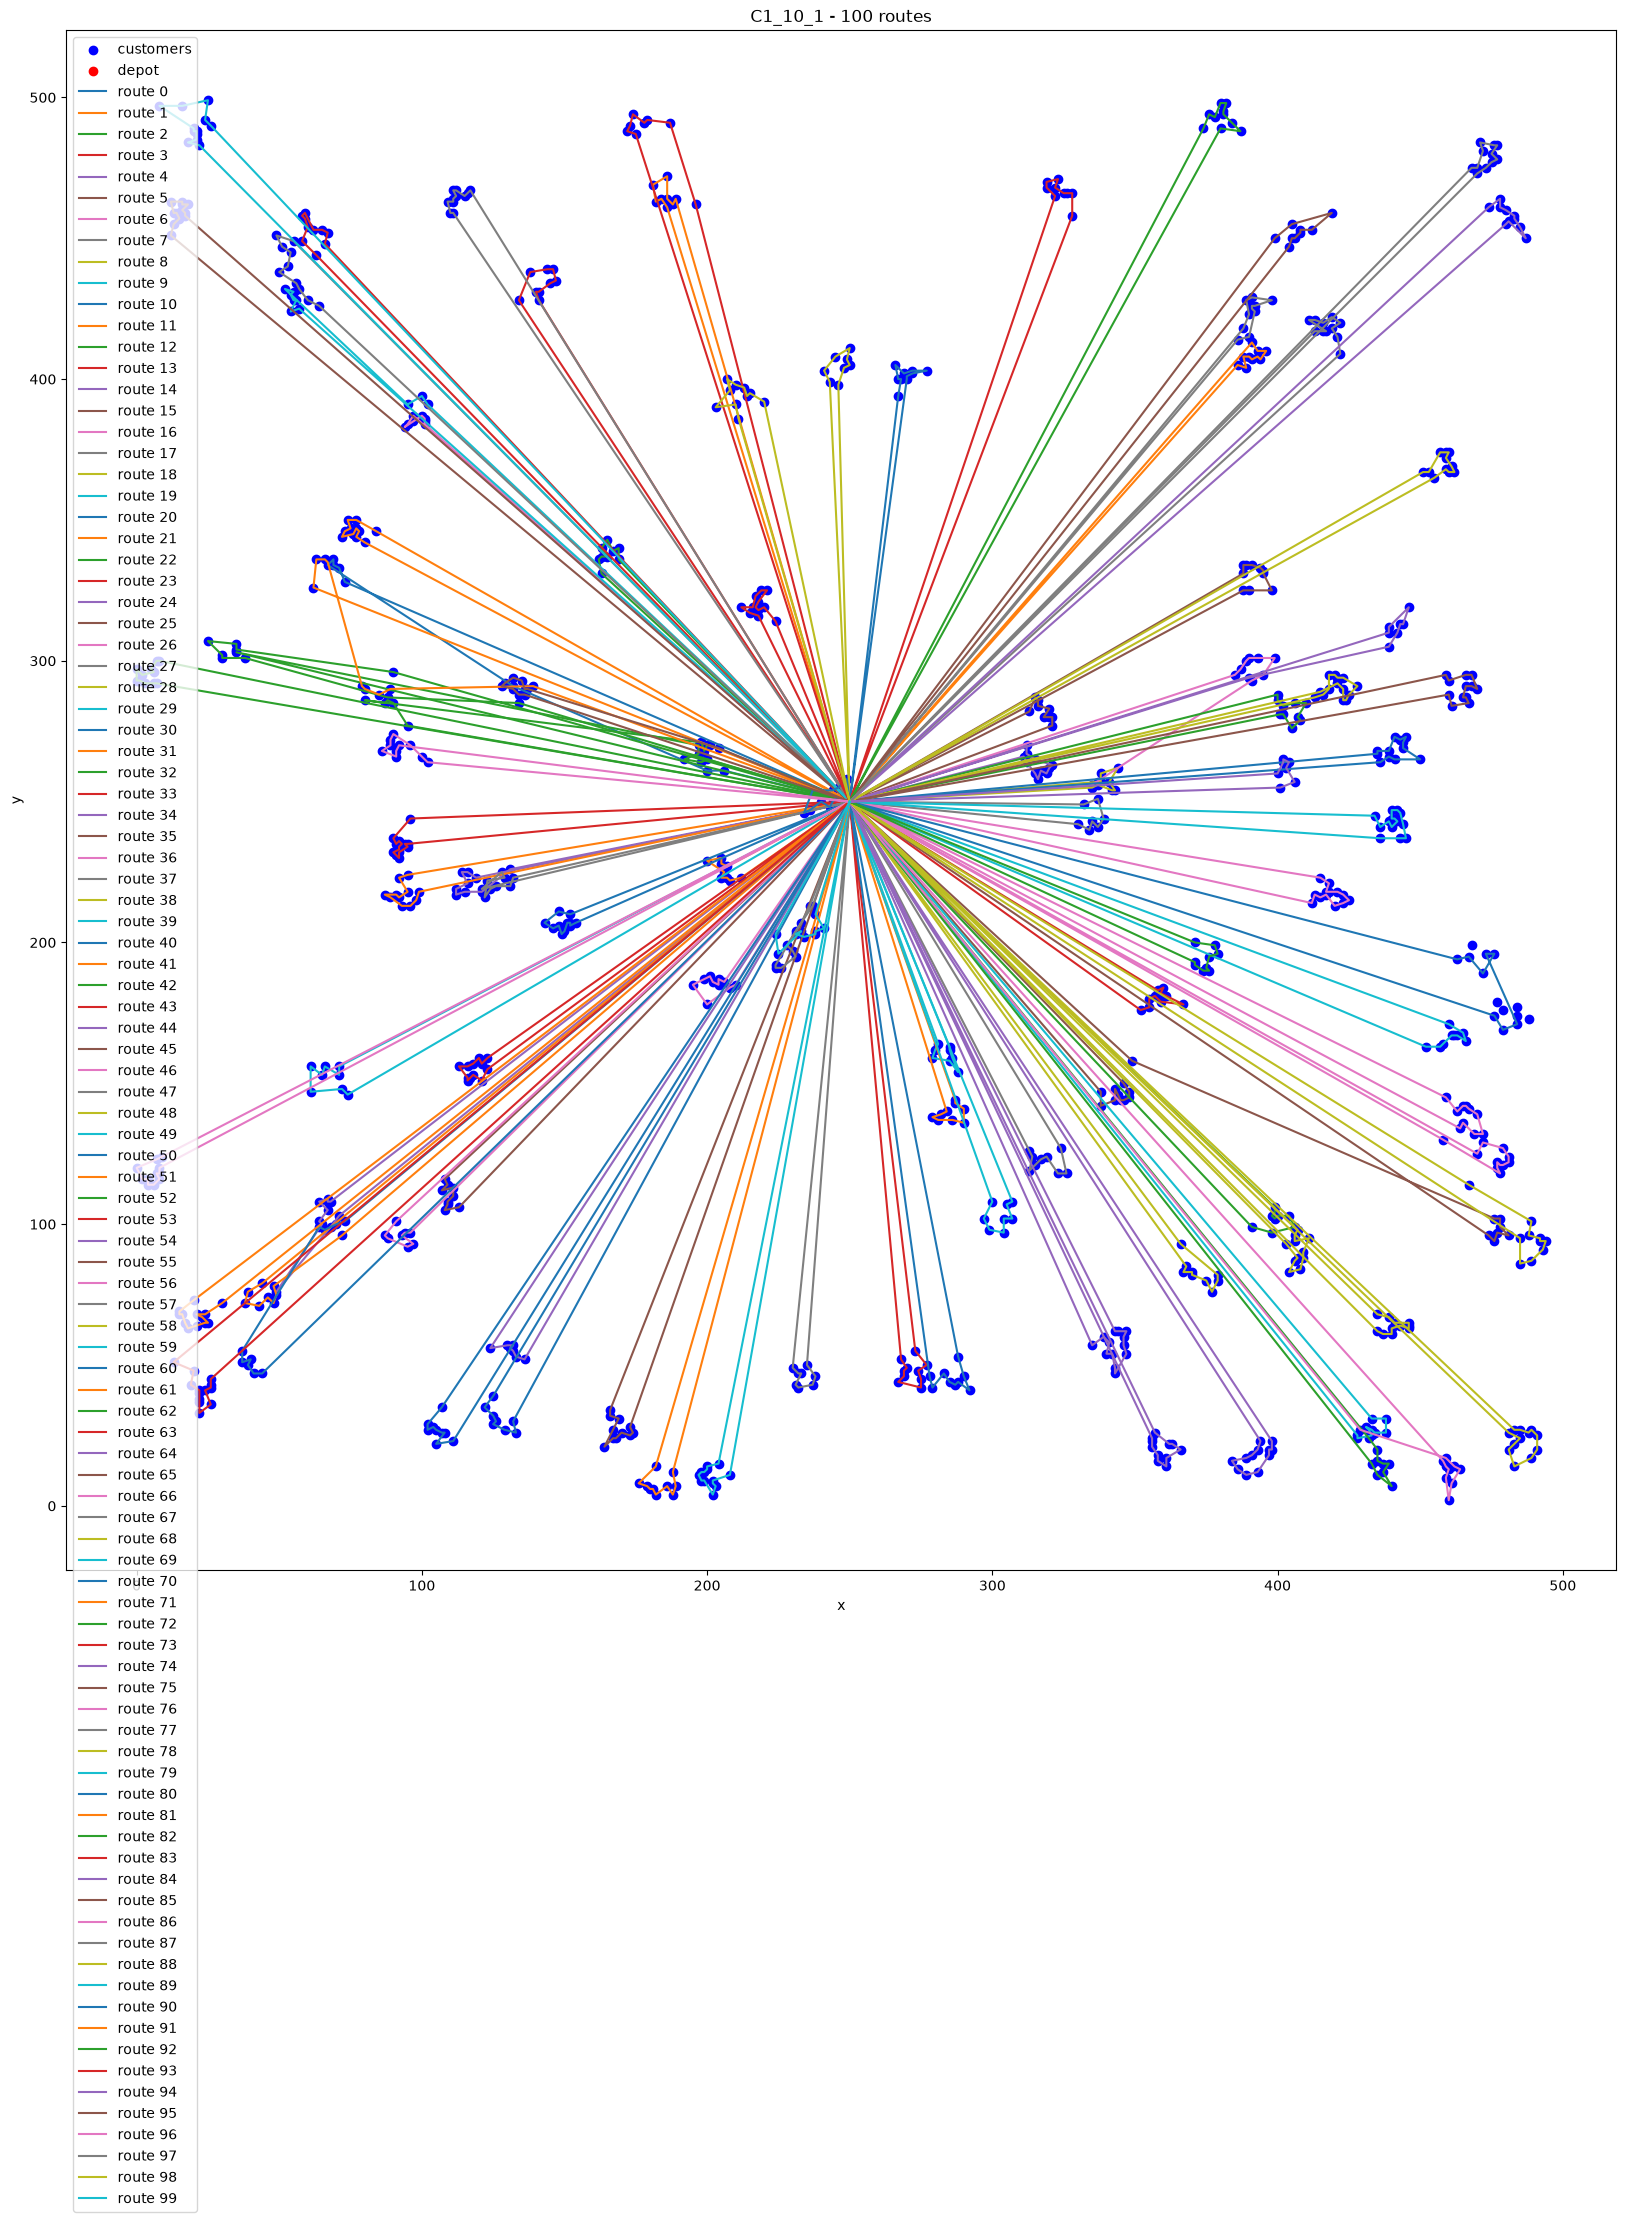

In [21]:
#first try 
inst = load_instance(f"{DATA_DIR}/C1_10_1.1000.100.vrptw")
alns_solution, alns_history = alns(inst, iterations=2000, seed=0, vehicle_cost=0.0, unassigned_penalty=1e4)
print("ALNS solution: distance =", alns_solution.distance(inst), ", #vehicles =", len(alns_solution.routes))
print(alns_solution.routes)
plot_route(inst, alns_solution.routes)

# **Experimental Study**



## Research questions

The questions below were fixed before running the experiments. Each one is answered by one experiment.

| | Question | Experiment |
|---|---|---|
| RQ1 | Which degree of destruction $q$ and which initial temperature $w$ should the ALNS use, and do they interact? | **T** (tuning) |
| RQ2 | How far from the best known solutions is the ALNS, for several iteration budgets, and does the tuned setting beat the default one at equal budget? | **B** (benchmark and budgets) |
| RQ3 | What does each destroy / repair operator contribute, and is the adaptive selection useful? | **A1** (ablation) |
| RQ4 | How do the operator weights evolve, and do they differ between clustered, random and mixed instances? | **A2** (weights) |
| RQ5 | What do the time windows and the limited fleet cost, in distance and in CO$_2$? | **C** (cost of the constraints) |
| RQ6 | How does the time per iteration grow with the number of customers, up to 1000? | **S** (scalability) |

## Environment and code version

In [8]:
import math, os, platform, subprocess, warnings
import importlib.metadata as metadata
import scipy
from scipy import stats
from statsmodels.stats.multitest import multipletests

def git(*args):
    try:
        return subprocess.run(["git", *args], capture_output=True, text=True).stdout.strip()
    except OSError:
        return "unknown"

environment = {"OS": platform.platform(), "CPU": platform.processor(), "logical cores": os.cpu_count(),
               "Python": platform.python_version(),
               **{p: metadata.version(p) for p in ("numpy", "pandas", "scipy", "statsmodels", "matplotlib", "vrplib")},
               "git commit": git("rev-parse", "--short", "HEAD"), "git branch": git("rev-parse", "--abbrev-ref", "HEAD")}
pd.DataFrame({"value": environment})

,value
OS,Windows-11-10.0.26300-SP0
CPU,"Intel64 Family 6 Model 186 Stepping 3, Genuine..."
logical cores,12
Python,3.14.3
numpy,2.5.3
pandas,3.0.6
scipy,1.18.1
statsmodels,0.15.0
matplotlib,3.11.2
vrplib,2.2.0


## Protocol

**Algorithm.** All runs use `alns_exp`, a copy of `alns`; the original is left unchanged. With the same seed and parameters, `alns_exp` returns exactly the same solution (checked below). It only adds the choice of the operators allowed (for A1), $T_0 = 0$ for pure hill climbing (for T), relaxed instances (for C) and extra logs.

**Instances and tuning / test split** (table below).
- *Tuning set*: C101 (100 customers) and C1_2_1 (200, Gehring & Homberger). The parameters $q$ and $w$ are chosen on these two instances only (experiment T).
- *Test set*: C102 (clustered), R101 (random), RC101 (mixed), all with 100 customers, and C1_10_1 (1000 customers). Every conclusion about quality is drawn on these instances, which were not used for tuning.
- *Scalability only*: C101-25 and C101-50, the first 25 and 50 customers of C101.
- `C1_2_1.txt` is the same instance as `C1_2_1.200.20.vrptw`, but with 50 vehicles instead of 20. We use the version with 20 vehicles, the fleet of the best known solution.

**Quality indicator.** $\text{gap} = 100\,(f - f_{BKS}) / f_{BKS}$ (Eq. 1), where $f$ = distance $+\ 10^4 \times$ (number of unserved customers).
- C101, R101 and RC101: $f_{BKS}$ is the cost of the provided `.sol` file, recomputed with our distances. For R101 and RC101, these are the best solutions for **total distance** (20 and 15 routes). This is also our objective, whereas the SINTEF table ranks solutions by number of vehicles first.
- C102, C1_2_1 and C1_10_1: values from the SINTEF tables (828.94; 2704.57 with 20 vehicles; 42478.95 with 100 vehicles). The fleet limit of the file equals the number of vehicles of the BKS, so comparing distances is fair.
- A run that leaves customers unserved gets a very large gap: each unserved customer adds about 600 % on a 100-customer instance and 24 % on C1_10_1. The mean gap is therefore always reported with the median gap and the share of feasible runs.

**Distances.** Euclidean distances in double precision, without rounding (`EXACT_2D`), and travel time = distance. This is the convention of the Solomon / Gehring & Homberger benchmark used by SINTEF ("distance and time should be calculated with double precision"). The integer rounding of CVRPLIB applies to the CVRP instances, not to these ones. Gaps may be slightly negative (−0.0003 %) because SINTEF rounds its BKS to two decimals.

**Budget.** The budget is a number of iterations (one iteration = one destroy + one repair), so every variant gets the same number of evaluations. 2000 iterations is the reference budget: about 1 min for 100 customers and 4 min for 1000 customers in serial. Experiment B also uses 500 and 1000 iterations. The cooling factor is recomputed from the budget, so $T$ always reaches $10^{-4} T_0$ at the last iteration. A shorter budget is therefore a separate run, not the beginning of a longer one.

**Seeds.** 20 seeds (0 to 19) for every pair (instance, configuration), the same seeds everywhere. The same seed gives the same initial solution for every variant, so the comparisons are paired.

**Statistics.** Rank tests by default (`scipy.stats`):
- paired Wilcoxon signed-rank test for two configurations;
- Friedman test (blocked by seed) for $k$ configurations;
- Fisher exact test for success rates (feasible runs);
- Holm correction for multiple tests (`statsmodels`);
- Vargha–Delaney $A_{12}$ effect size (0.56 / 0.64 / 0.71 = small / medium / large);
- 95 % confidence interval of the mean gap (Student $t$).

**Runtime.** Experiments T, B, A1 and C were run with 11 processes in parallel on the machine described above. Their times are inflated by this load (about ×2.5), so they can only be compared with each other. Experiment S was run alone. Each experiment saves its results in `results/` and reloads them the next time the notebook runs; delete a file to recompute it.

In [9]:
# ---- Copy of alns() for the experimental study ----
# Same algorithm, same random draws. Additions:
#   destroy / repair : names of the operators allowed (ablation, single pair)
#   start_worse = 0  : T = 0, i.e. pure hill climbing
#   logs             : weights per operator name, new bests per operator, acceptance of worse candidates,
#                      iteration of the last improvement, initial solution, time spent on the initial solution
def alns_exp(inst, destroy=None, repair=None, **overrides):
    params = {**DEFAULT_PARAMS, **overrides}
    rng = np.random.default_rng(params["seed"])
    t0 = time.perf_counter()
    D = [f for f in DESTROY if destroy is None or f.__name__ in destroy]
    R = [f for f in REPAIR if repair is None or f.__name__ in repair]
    dnames, rnames = [f.__name__ for f in D], [f.__name__ for f in R]

    # Initial solution: always regret-2, even if regret-2 is removed from the pool (same start for every variant)
    empty = Solution([], range(1, inst["n_customers"] + 1))
    current = regret2_repair(empty, inst, rng, params)
    f_current = current.objective(inst, params)
    best, f_best = current.copy(), f_current
    t_init = time.perf_counter() - t0

    T = -params["start_worse"] * f_current / np.log(params["start_accept"])
    cooling = params["end_temp_frac"] ** (1.0 / params["iterations"])

    nD, nR = len(D), len(R)
    wD, wR = np.ones(nD), np.ones(nR)
    scoreD, scoreR = np.zeros(nD), np.zeros(nR)
    usedD, usedR = np.zeros(nD), np.zeros(nR)
    newD, newR = np.zeros(nD, int), np.zeros(nR, int)
    history = {"current": [], "best": [], "worse_acc": [], "initial": f_current, "t_init": t_init,
               "initial_dist": current.distance(inst), "initial_unassigned": len(current.unassigned),
               "wD": [dict(zip(dnames, wD))], "wR": [dict(zip(rnames, wR))], "last_improvement": 0}

    for it in range(params["iterations"]):
        if params["time_limit"] and time.perf_counter() - t0 > params["time_limit"]:
            break

        i = rng.choice(nD, p=wD / wD.sum())
        j = rng.choice(nR, p=wR / wR.sum())
        candidate = R[j](D[i](current, inst, rng, params), inst, rng, params)
        f_cand = candidate.objective(inst, params)

        score, worse_acc = 0, np.nan                        # worse_acc: 1/0 if a strictly worse candidate is accepted/rejected
        if f_cand < f_best - 1e-9:
            best, f_best = candidate.copy(), f_cand
            current, f_current = candidate, f_cand
            score = params["sigma1"]
            newD[i] += 1; newR[j] += 1
            history["last_improvement"] = it + 1
        elif f_cand < f_current - 1e-9:
            current, f_current = candidate, f_cand
            score = params["sigma2"]
        else:
            worse = f_cand > f_current + 1e-9
            worse_acc = 0.0 if worse else np.nan
            if T > 0 and rng.random() < np.exp(-(f_cand - f_current) / T):   # T = 0: hill climbing, never accept
                current, f_current = candidate, f_cand
                score = params["sigma3"]
                worse_acc = 1.0 if worse else np.nan

        scoreD[i] += score; scoreR[j] += score
        usedD[i] += 1;      usedR[j] += 1
        T *= cooling
        history["current"].append(f_current)
        history["best"].append(f_best)
        history["worse_acc"].append(worse_acc)

        if (it + 1) % params["segment"] == 0:
            r = params["reaction"]
            wD = np.where(usedD > 0, (1 - r) * wD + r * scoreD / np.maximum(usedD, 1), wD)
            wR = np.where(usedR > 0, (1 - r) * wR + r * scoreR / np.maximum(usedR, 1), wR)
            wD, wR = np.maximum(wD, 0.05), np.maximum(wR, 0.05)
            scoreD[:] = scoreR[:] = usedD[:] = usedR[:] = 0
            history["wD"].append(dict(zip(dnames, wD)))
            history["wR"].append(dict(zip(rnames, wR)))

    history["newbestD"] = dict(zip(dnames, newD.tolist()))
    history["newbestR"] = dict(zip(rnames, newR.tolist()))
    history["runtime"] = time.perf_counter() - t0
    return best, history


DNAMES = [f.__name__ for f in DESTROY]
REPAIR_NAMES = [f.__name__ for f in REPAIR]
SEEDS = range(20)

# ---- Instances: role in the study, label and reference value ----
INSTANCE_FILES = {
    "C101.txt": "tuning", "C1_2_1.200.20.vrptw": "tuning",
    "C102.100.10.vrptw": "test", "R101.txt": "test", "RC101.txt": "test", "C1_10_1.1000.100.vrptw": "test",
    "C101.25.3.vrptw": "scalability only", "C101.50.5.vrptw": "scalability only",
}
LABELS = {"C101.25.3.vrptw": "C101-25", "C101.50.5.vrptw": "C101-50"}   # these files are also named "C101" inside
SOL_FILES = {"C101": "C101.sol", "R101": "R101.sol", "RC101": "RC101.sol"}   # cost recomputed with our distances
SINTEF_BKS = {"C102": 828.94, "C1_2_1": 2704.57, "C1_10_1": 42478.95}          # rounded to 2 decimals by SINTEF

INSTANCES = {}
def get_instance(file, relax=None):
    # Each instance is read once and never modified: a relaxed version is a separate copy
    if (file, relax) not in INSTANCES:
        if relax is None:
            inst = load_instance(f"{DATA_DIR}/{file}")
            inst["label"] = LABELS.get(file, inst["name"])
        else:
            inst = dict(get_instance(file))
            if relax == "no time windows":
                inst["ready"] = np.zeros_like(inst["ready"])
                inst["due"] = np.full_like(inst["due"], 1e9)
            elif relax == "unlimited fleet":
                inst["n_vehicles"] = inst["n_customers"]
            else:
                raise ValueError(f"unknown relaxation: {relax}")
        INSTANCES[(file, relax)] = inst
    return INSTANCES[(file, relax)]


BKS = {}
for f in INSTANCE_FILES:
    inst = get_instance(f)
    if inst["label"] in SOL_FILES:
        BKS[inst["label"]] = load_bks(f"{DATA_DIR}/{SOL_FILES[inst['label']]}", inst)[0]
    elif inst["label"] in SINTEF_BKS:
        BKS[inst["label"]] = SINTEF_BKS[inst["label"]]

COVERAGE_ERROR = "each customer must be visited exactly once"   # reported by check_solution when customers are unserved


def run_job(job):
    # job = (instance file, seed, variant label, arguments of alns_exp, names of the traces to keep)
    file, seed, label, kw, keep = job
    kw = dict(kw)
    inst = get_instance(file, kw.pop("relax", None))
    sol, h = alns_exp(inst, seed=seed, **kw)
    dist, errors = check_solution(inst, sol.routes)       # independent check: cost recomputed from the routes
    obj = dist + DEFAULT_PARAMS["unassigned_penalty"] * len(sol.unassigned)
    rec = dict(file=file, instance=inst["label"], n=inst["n_customers"], variant=label, seed=seed,
               iterations=len(h["current"]), obj=obj, dist=dist, vehicles=len(sol.routes),
               unassigned=len(sol.unassigned), feasible=not errors,
               violations=sum(e != COVERAGE_ERROR for e in errors), cost_mismatch=abs(dist - sol.distance(inst)),
               initial_dist=h["initial_dist"], initial_unassigned=h["initial_unassigned"],
               runtime=h["runtime"], iter_time=(h["runtime"] - h["t_init"]) / max(1, len(h["current"])),
               last_improvement=h["last_improvement"])
    rec["gap"] = 100 * (obj - BKS[rec["instance"]]) / BKS[rec["instance"]] if rec["instance"] in BKS else np.nan
    for k in ("current", "best", "worse_acc"):             # traces are large: kept only when needed
        if k not in keep:
            h.pop(k)
    return rec, h


def run_many(jobs):
    # Independent runs: this loop can be replaced by a process pool
    return [run_job(j) for j in jobs]


def cached(name, jobs):
    # Results are saved in results/<name>.pkl and reloaded on the next run (delete the file to recompute)
    path = f"results/{name}.pkl"
    if not os.path.exists(path):
        os.makedirs("results", exist_ok=True)
        out = run_many(jobs)
        pd.to_pickle((pd.DataFrame([r for r, _ in out]), [h for _, h in out]), path)
    return pd.read_pickle(path)


# ---- Statistics ----
def ci95(x):
    # 95 % confidence interval of the mean (Student t)
    x = np.asarray(x, float)
    if len(x) < 2 or np.std(x) == 0:
        return x.mean(), x.mean()
    return stats.t.interval(0.95, len(x) - 1, loc=x.mean(), scale=stats.sem(x))


def wilcoxon_p(x, y):
    # Paired Wilcoxon signed-rank test; differences below 1e-6 are ties (dropped). p = 1 if all pairs are equal
    d = np.round(np.asarray(x, float) - np.asarray(y, float), 6)
    return 1.0 if np.all(d == 0) else stats.wilcoxon(d).pvalue


def fisher_p(a, b):
    # Fisher exact test on two success rates (a, b: boolean arrays)
    a, b = np.asarray(a, bool), np.asarray(b, bool)
    return stats.fisher_exact([[a.sum(), (~a).sum()], [b.sum(), (~b).sum()]]).pvalue


def friedman_p(groups):
    # Friedman test over k paired configurations (blocked by seed); nan when every value is identical
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        try:
            return stats.friedmanchisquare(*groups).pvalue
        except ValueError:
            return np.nan


def holm(p):
    return multipletests(p, method="holm")[1]


def a12(x, y):
    # Vargha-Delaney A12: P(X > Y) + 0.5 P(X = Y). For gaps, A12 > 0.5 means X is worse than Y
    x, y = np.round(np.asarray(x, float), 6)[:, None], np.round(np.asarray(y, float), 6)[None, :]
    return (x > y).mean() + 0.5 * (x == y).mean()


def describe(g):
    # Descriptive statistics of a group of runs (one instance, one configuration)
    lo, hi = ci95(g.gap)
    return dict(runs=len(g), best_cost=g.obj.min(), mean_cost=g.obj.mean(), median_cost=g.obj.median(),
                std_cost=g.obj.std(), mean_gap=g.gap.mean(), median_gap=g.gap.median(), std_gap=g.gap.std(),
                ci95_low=lo, ci95_high=hi, best_gap=g.gap.min(), feasible_pct=100 * g.feasible.mean(),
                unserved=g.unassigned.mean(), vehicles=g.vehicles.mean(), time_s=g.runtime.mean())


def compare(df, ref):
    # One row per (instance, variant) vs the reference variant: descriptive stats, A12, Wilcoxon and Fisher (Holm)
    rows = []
    for name, g in df.groupby("instance", sort=False):
        base = g[g.variant == ref].sort_values("seed")
        for v, gv in g.groupby("variant", sort=False):
            gv = gv.sort_values("seed")
            rows.append(dict(instance=name, variant=v, **describe(gv), A12=a12(gv.gap, base.gap),
                             p_wilcoxon=np.nan if v == ref else wilcoxon_p(gv.gap, base.gap),
                             p_fisher=np.nan if v == ref else fisher_p(gv.feasible, base.feasible)))
    t = pd.DataFrame(rows)
    for _, g in t[t.variant != ref].groupby("instance"):
        t.loc[g.index, "p_wilcoxon_holm"] = holm(g.p_wilcoxon)
        t.loc[g.index, "p_fisher_holm"] = holm(g.p_fisher)
    return t


assert abs(ci95([1.0, 2.0, 3.0])[0] - (2 - 4.303 * 1 / math.sqrt(3))) < 1e-3
assert a12([2, 2], [1, 1]) == 1.0 and wilcoxon_p([1, 2], [1, 2]) == 1.0

# Checks: the copy reproduces alns(), and the same job gives the same result twice (no hidden state between runs)
inst = get_instance("C101.txt")
s1, _ = alns(inst, iterations=200, seed=1)
s2, _ = alns_exp(inst, iterations=200, seed=1)
assert s1.routes == s2.routes
job = ("R101.txt", 3, "check", dict(iterations=100), ())
assert run_job(job)[0]["obj"] == run_job(job)[0]["obj"]
print("alns_exp reproduces alns, and runs are reproducible from the seed")

alns_exp reproduces alns, and runs are reproducible from the seed


In [10]:
# Instances used in the study
rows = []
for f, role in INSTANCE_FILES.items():
    inst = get_instance(f)
    name = inst["label"]
    kind = "mixed (RC)" if name.startswith("RC") else "random (R)" if name.startswith("R") else "clustered (C)"
    rows.append(dict(instance=name, file=f, role=role, n=inst["n_customers"], distribution=kind,
                     vehicles=inst["n_vehicles"], capacity=inst["capacity"],
                     demand_over_fleet_capacity=inst["demand"].sum() / (inst["n_vehicles"] * inst["capacity"]),
                     horizon=inst["due"][0], mean_window_width=(inst["due"][1:] - inst["ready"][1:]).mean(),
                     BKS=BKS.get(name, np.nan)))
instances_table = pd.DataFrame(rows)
instances_table.round(3)

,instance,file,role,n,distribution,vehicles,capacity,demand_over_fleet_capacity,horizon,mean_window_width,BKS
0,C101,C101.txt,tuning,100,clustered (C),25,200.0,0.362,1236.0,60.760,828.937
1,C1_2_1,C1_2_1.200.20.vrptw,tuning,200,clustered (C),20,200.0,0.882,1351.0,60.355,2704.570
2,C102,C102.100.10.vrptw,test,100,clustered (C),10,200.0,0.905,1236.0,325.690,828.940
3,R101,R101.txt,test,100,random (R),25,200.0,0.292,230.0,10.000,1642.877
4,RC101,RC101.txt,test,100,mixed (RC),25,200.0,0.345,240.0,30.000,1623.557
5,C1_10_1,C1_10_1.1000.100.vrptw,test,1000,clustered (C),100,200.0,0.897,1824.0,59.646,42478.950
6,C101-25,C101.25.3.vrptw,scalability only,25,clustered (C),3,200.0,0.767,1236.0,60.440,NaN
7,C101-50,C101.50.5.vrptw,scalability only,50,clustered (C),5,200.0,0.860,1236.0,60.140,NaN


## Experiment T: degree of destruction × acceptance (tuning, RQ1)

**Design.** Full factorial design on the tuning set (C101, C1_2_1), 20 seeds, 2000 iterations:
- $q$ range ∈ {[5 %, 15 %], [10 %, 30 %], [20 %, 40 %]} of $n$, without the cap of 40 customers;
- initial temperature $w$ ∈ {0 (hill climbing), 1 %, 5 %, 20 %}, where $T_0$ accepts a solution $w$ % worse with probability 0.5.

The 12 configurations are compared with a Friedman test per instance, and the feasibility rates with Fisher tests. The traces of seed 0 are kept for the trajectory plots.

*Why the cap is removed.* In `removal_size`, $q_{max} = \max(q_{min}, \min(40, 0.3n))$. For $n = 1000$, $q_{min} = 50 > 40$, so the default $q$ is always exactly 50.

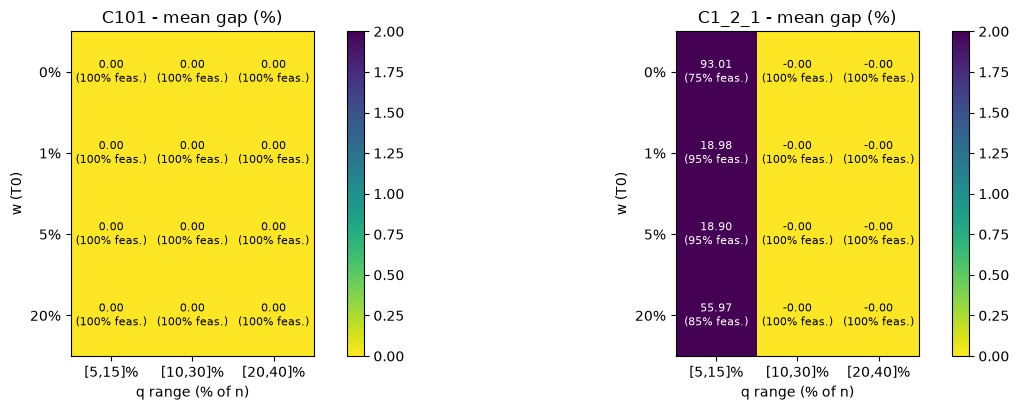

C101: Friedman test over the 12 configurations, all runs identical, no test needed
C1_2_1: Friedman test over the 12 configurations, p = 9.71e-09


,instance,q,w,mean_gap,median_gap,ci95_low,ci95_high,feasible_pct,BKS_reached_pct,last_improvement,time_s
0,C101,"[5,15]%",0%,0.000,0.000,0.000,0.000,100.0,100.0,0.00,17.702
1,C101,"[5,15]%",1%,0.000,0.000,0.000,0.000,100.0,100.0,0.00,17.597
2,C101,"[5,15]%",5%,0.000,0.000,0.000,0.000,100.0,100.0,0.00,17.702
3,C101,"[5,15]%",20%,0.000,0.000,0.000,0.000,100.0,100.0,0.00,17.731
4,C101,"[10,30]%",0%,0.000,0.000,0.000,0.000,100.0,100.0,0.00,37.317
5,C101,"[10,30]%",1%,0.000,0.000,0.000,0.000,100.0,100.0,0.00,37.919
6,C101,"[10,30]%",5%,0.000,0.000,0.000,0.000,100.0,100.0,0.00,37.408
7,C101,"[10,30]%",20%,0.000,0.000,0.000,0.000,100.0,100.0,0.00,37.737
8,C101,"[20,40]%",0%,0.000,0.000,0.000,0.000,100.0,100.0,0.00,62.925
9,C101,"[20,40]%",1%,0.000,0.000,0.000,0.000,100.0,100.0,0.00,63.711


In [11]:
TUNING_FILES = [f for f, r in INSTANCE_FILES.items() if r == "tuning"]
Q_RANGES = {"[5,15]%": (0.05, 0.15), "[10,30]%": (0.10, 0.30), "[20,40]%": (0.20, 0.40)}
W_VALUES = [0.0, 0.01, 0.05, 0.20]

jobs = [(f, s, f"q {qn} | w {w:.0%}", dict(q_min_frac=a, q_max_frac=b, q_max_abs=10**9, start_worse=w, iterations=2000),
         ("current", "best", "worse_acc") if s == 0 else ())
        for f in TUNING_FILES for s in SEEDS for qn, (a, b) in Q_RANGES.items() for w in W_VALUES]
tun, tun_hist = cached("T_q_temperature", jobs)
tun["q"] = tun.variant.str.extract(r"q (\S+)")[0]
tun["w"] = tun.variant.str.extract(r"w (\S+)")[0]
tun["success"] = tun.gap <= 0.01                           # BKS reached (up to the rounding of the BKS)

fig, axes = plt.subplots(1, len(TUNING_FILES), figsize=(6.5 * len(TUNING_FILES), 4.2))
for ax, (name, g) in zip(axes, tun.groupby("instance", sort=False)):
    H = g.pivot_table(index="w", columns="q", values="gap", aggfunc="mean").loc[[f"{w:.0%}" for w in W_VALUES], list(Q_RANGES)]
    F = g.pivot_table(index="w", columns="q", values="feasible", aggfunc="mean").loc[H.index, H.columns]
    im = ax.imshow(np.minimum(H.values, 2), cmap="viridis_r", vmin=0, vmax=2)   # colours capped at 2 % so that
    for (y, x), v in np.ndenumerate(H.values):                                  # one infeasible cell does not hide the rest
        ax.text(x, y, f"{v:.2f}\n({F.values[y, x]:.0%} feas.)", ha="center", va="center", fontsize=8,
                color="w" if v > 1 else "k")
    ax.set_xticks(range(len(H.columns)), H.columns); ax.set_yticks(range(len(H.index)), H.index)
    ax.set_xlabel("q range (% of n)"); ax.set_ylabel("w (T0)"); ax.set_title(f"{name} - mean gap (%)")
    fig.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

for name, g in tun.groupby("instance", sort=False):
    groups = [gv.sort_values("seed").gap.to_numpy() for _, gv in g.groupby("variant", sort=False)]
    p = friedman_p(groups)
    print(f"{name}: Friedman test over the 12 configurations, " + ("all runs identical, no test needed" if np.isnan(p) else f"p = {p:.3g}"))

tun_table = pd.DataFrame([dict(instance=name, q=gv.q.iloc[0], w=gv.w.iloc[0], **describe(gv),
                               BKS_reached_pct=100 * gv.success.mean(), last_improvement=gv.last_improvement.mean())
                          for (name, v), gv in tun.groupby(["instance", "variant"], sort=False)])
tun_table[["instance", "q", "w", "mean_gap", "median_gap", "ci95_low", "ci95_high", "feasible_pct",
           "BKS_reached_pct", "last_improvement", "time_s"]].round(3)

In [12]:
# Effect of the factors on the success rate (BKS reached) on C1_2_1: Fisher exact tests, Holm correction
g = tun[tun.instance == "C1_2_1"]
tests = {"q [5,15]% vs q [10,30]% (all w)": (g[g.q == "[5,15]%"].success, g[g.q == "[10,30]%"].success),
         "q [10,30]% vs q [20,40]% (all w)": (g[g.q == "[10,30]%"].success, g[g.q == "[20,40]%"].success),
         "w 0% vs w 5% (q [5,15]%)": (g[(g.q == "[5,15]%") & (g.w == "0%")].success, g[(g.q == "[5,15]%") & (g.w == "5%")].success)}
p = [fisher_p(a, b) for a, b in tests.values()]
pd.DataFrame({"success rate A": [a.mean() for a, _ in tests.values()], "success rate B": [b.mean() for _, b in tests.values()],
              "p (Fisher)": p, "p (Holm)": holm(p)}, index=list(tests)).round({"success rate A": 2, "success rate B": 2})

,success rate A,success rate B,p (Fisher),p (Holm)
"q [5,15]% vs q [10,30]% (all w)",0.55,1.0,1.720157e-13,5.160470e-13
"q [10,30]% vs q [20,40]% (all w)",1.00,1.0,1.000000e+00,1.000000e+00
"w 0% vs w 5% (q [5,15]%)",0.65,0.6,1.000000e+00,1.000000e+00


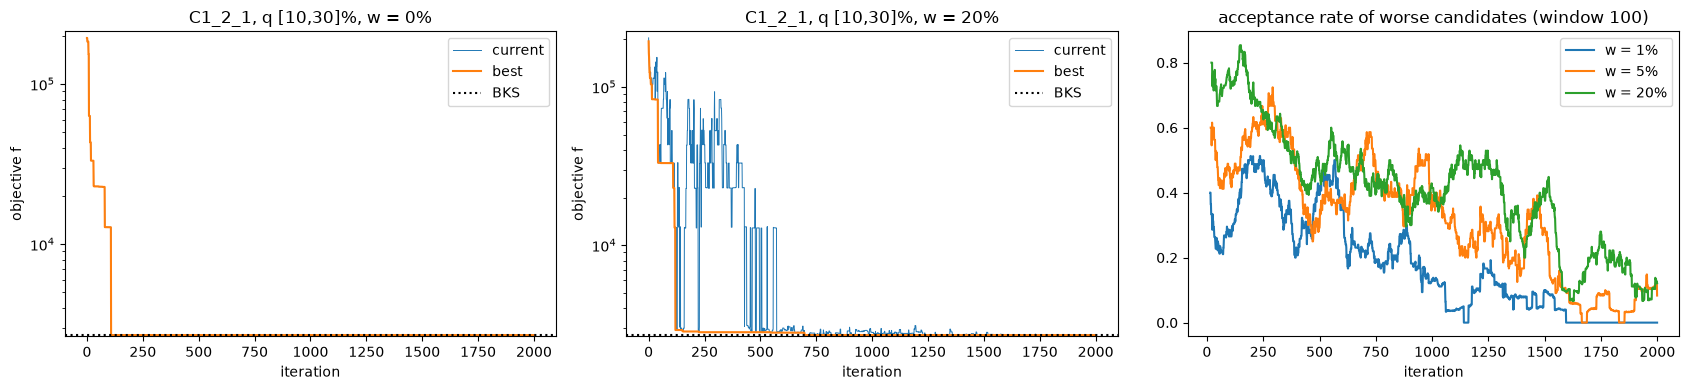

In [13]:
# Trajectories (seed 0, C1_2_1, q in [10,30]%) and acceptance rate of strictly worse candidates
traced = {(r.instance, r.variant): tun_hist[i] for i, r in tun.iterrows() if r.seed == 0}
name = "C1_2_1"
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for w, ax in zip(["0%", "20%"], axes[:2]):
    h = traced[(name, f"q [10,30]% | w {w}")]
    ax.plot(h["current"], lw=.7, label="current"); ax.plot(h["best"], lw=1.5, label="best")
    ax.axhline(BKS[name], color="k", ls=":", label="BKS")
    ax.set_yscale("log")                                    # unserved customers cost 10^4 each: log scale
    ax.set_ylim(BKS[name] * 0.98, max(h["current"]) * 1.1); ax.set_ylabel("objective f")
    ax.set_title(f"{name}, q [10,30]%, w = {w}"); ax.set_xlabel("iteration"); ax.legend()
for w in W_VALUES[1:]:
    h = traced[(name, f"q [10,30]% | w {w:.0%}")]
    axes[2].plot(pd.Series(h["worse_acc"]).rolling(100, min_periods=10).mean(), label=f"w = {w:.0%}")
axes[2].set_title("acceptance rate of worse candidates (window 100)"); axes[2].set_xlabel("iteration")
axes[2].legend(); plt.tight_layout(); plt.show()

### Analysis of T

- **C101 does not discriminate.** The initial regret-2 solution is already the BKS (828.94, 10 vehicles), so the 240 runs all stay at gap 0 and the Friedman test is not applicable. C101 only tells us that no setting degrades a good start.
- **On C1_2_1, $q$ is the dominant parameter.** The Friedman test over the 12 configurations gives $p = 9.7 \times 10^{-9}$. With $q \in [10, 30]\,\%$ or $[20, 40]\,\%$, **all 160 runs reach the BKS** (2704.57 with 20 vehicles), whatever $w$. With $q \in [5, 15]\,\%$, only 44 of 80 runs do (Fisher $p = 1.7 \times 10^{-13}$, Holm-corrected $p < 10^{-12}$), and 5 to 25 % of the runs still leave customers unserved after 2000 iterations. Removing 10 to 20 customers out of 200 is not enough to move a whole cluster to another route.
- **$w$ has no significant effect** (Fisher test of $w = 0\,\%$ vs $w = 5\,\%$ at $q \in [5,15]\,\%$: $p = 1$). The trajectories explain why. The initial solution of C1_2_1 leaves 19 customers unserved, so $f(s_0) \approx 1.9 \times 10^5$ and $T_0 = -w f(s_0) / \ln 0.5$ is computed on the penalty, not on the distance: it is 50 to 70 times too large for the distance scale. With $w = 20\,\%$, the current solution oscillates between $10^4$ and $10^5$ for 500 iterations (pure diversification), and the acceptance rate of worse candidates stays above 40 % until iteration 1300. With $w = 0\,\%$ (pure descent), the BKS is reached at iteration ~110. In other words, a large $q$ already gives enough diversification on this instance, and the temperature only delays the intensification phase.
- **Cost of a larger $q$.** $[20, 40]\,\%$ is as good as $[10, 30]\,\%$ but 1.7 times slower (271 s vs 161 s per run, mean of the parallel runs), because the regret repairs are quadratic in the number of removed customers.

**Choice for the next experiments (tuned configuration):** $q \in [10, 30]\,\%$ of $n$, without the cap of 40 customers, and $w = 5\,\%$ unchanged (no evidence to change it). The tuning set (C101, C1_2_1) is not used to evaluate this choice: it is evaluated on the test instances in B.

## Experiment B: benchmark and budgets (RQ2)

**Design.** Two configurations:
- **default**: the parameters of section 8 ($q$ between 5 % and 30 % of $n$ capped at 40, $w = 5\,\%$);
- **tuned**: the setting chosen in experiment T ($q \in [10\,\%, 30\,\%]$ of $n$ without a cap, $w = 5\,\%$).

They are run with 500, 1000 and 2000 iterations on the five instances of 100 and 200 customers, 20 seeds each. On C1_10_1, only the default configuration with 2000 iterations is run: with the tuned $q$ (100 to 300 customers per iteration), a run would last more than 30 min.

The benchmark table uses the reference budget of 2000 iterations. The project targets a mean gap below 5 % for $n < 100$ and below 7 % for $n < 200$.

In [14]:
TUNED = dict(q_min_frac=0.10, q_max_frac=0.30, q_max_abs=10**9, start_worse=0.05)   # chosen in experiment T
CONFIGS = {"default": {}, "tuned": TUNED}
BUDGETS = [500, 1000, 2000]
SMALL_FILES = [f for f, r in INSTANCE_FILES.items() if r != "scalability only" and get_instance(f)["n_customers"] <= 200]

jobs = [(f, s, f"{c} | {b}", dict(kw, iterations=b), ("best",) if b == max(BUDGETS) else ())
        for f in SMALL_FILES for s in SEEDS for c, kw in CONFIGS.items() for b in BUDGETS]
jobs += [("C1_10_1.1000.100.vrptw", s, "default | 2000", dict(iterations=2000), ("best",)) for s in SEEDS]
bench, bench_hist = cached("B_benchmark_budgets", jobs)
bench["config"] = bench.variant.str.split(" | ", regex=False).str[0]
bench["budget"] = bench.variant.str.split(" | ", regex=False).str[1].astype(int)


def target(n):
    return 5.0 if n < 100 else 7.0 if n < 200 else np.nan


rows = []
for (name, c), g in bench[bench.budget == 2000].groupby(["instance", "config"], sort=False):
    rows.append(dict(instance=name, n=g.n.iloc[0], config=c, BKS=BKS[name], **describe(g),
                     target_gap=target(g.n.iloc[0])))
benchmark = pd.DataFrame(rows)
benchmark["target_met"] = np.where(benchmark.target_gap.isna(), "no target", benchmark.mean_gap < benchmark.target_gap)
benchmark[["instance", "n", "config", "BKS", "best_cost", "mean_cost", "median_cost", "std_cost", "mean_gap",
           "median_gap", "ci95_low", "ci95_high", "best_gap", "feasible_pct", "vehicles", "time_s",
           "target_gap", "target_met"]].round(3)

,instance,n,config,BKS,best_cost,mean_cost,median_cost,std_cost,mean_gap,median_gap,ci95_low,ci95_high,best_gap,feasible_pct,vehicles,time_s,target_gap,target_met
0,C101,100,default,828.937,828.937,828.937,828.937,0.000,0.000,0.000,0.000,0.000,0.000,100.0,10.00,33.874,7.0,True
1,C101,100,tuned,828.937,828.937,828.937,828.937,0.000,0.000,0.000,0.000,0.000,0.000,100.0,10.00,38.582,7.0,True
2,C1_2_1,200,default,2704.570,2704.568,2710.746,2704.568,21.192,0.228,-0.000,-0.138,0.595,-0.000,100.0,20.00,84.627,NaN,no target
3,C1_2_1,200,tuned,2704.570,2704.568,2704.568,2704.568,0.000,-0.000,-0.000,-0.000,-0.000,-0.000,100.0,20.00,146.014,NaN,no target
4,C102,100,default,828.940,828.937,828.937,828.937,0.000,-0.000,-0.000,-0.000,-0.000,-0.000,100.0,10.00,36.203,7.0,True
5,C102,100,tuned,828.940,828.937,828.937,828.937,0.000,-0.000,-0.000,-0.000,-0.000,-0.000,100.0,10.00,41.567,7.0,True
6,R101,100,default,1642.877,1643.089,1649.881,1647.051,6.549,0.426,0.254,0.240,0.613,0.013,100.0,19.85,46.636,7.0,True
7,R101,100,tuned,1642.877,1642.877,1648.639,1646.142,6.058,0.351,0.199,0.178,0.523,0.000,100.0,19.90,52.233,7.0,True
8,RC101,100,default,1623.557,1647.532,1666.448,1664.427,10.881,2.642,2.517,2.328,2.955,1.477,100.0,16.20,38.574,7.0,True
9,RC101,100,tuned,1623.557,1631.343,1661.750,1661.417,9.270,2.352,2.332,2.085,2.620,0.480,100.0,16.10,42.642,7.0,True


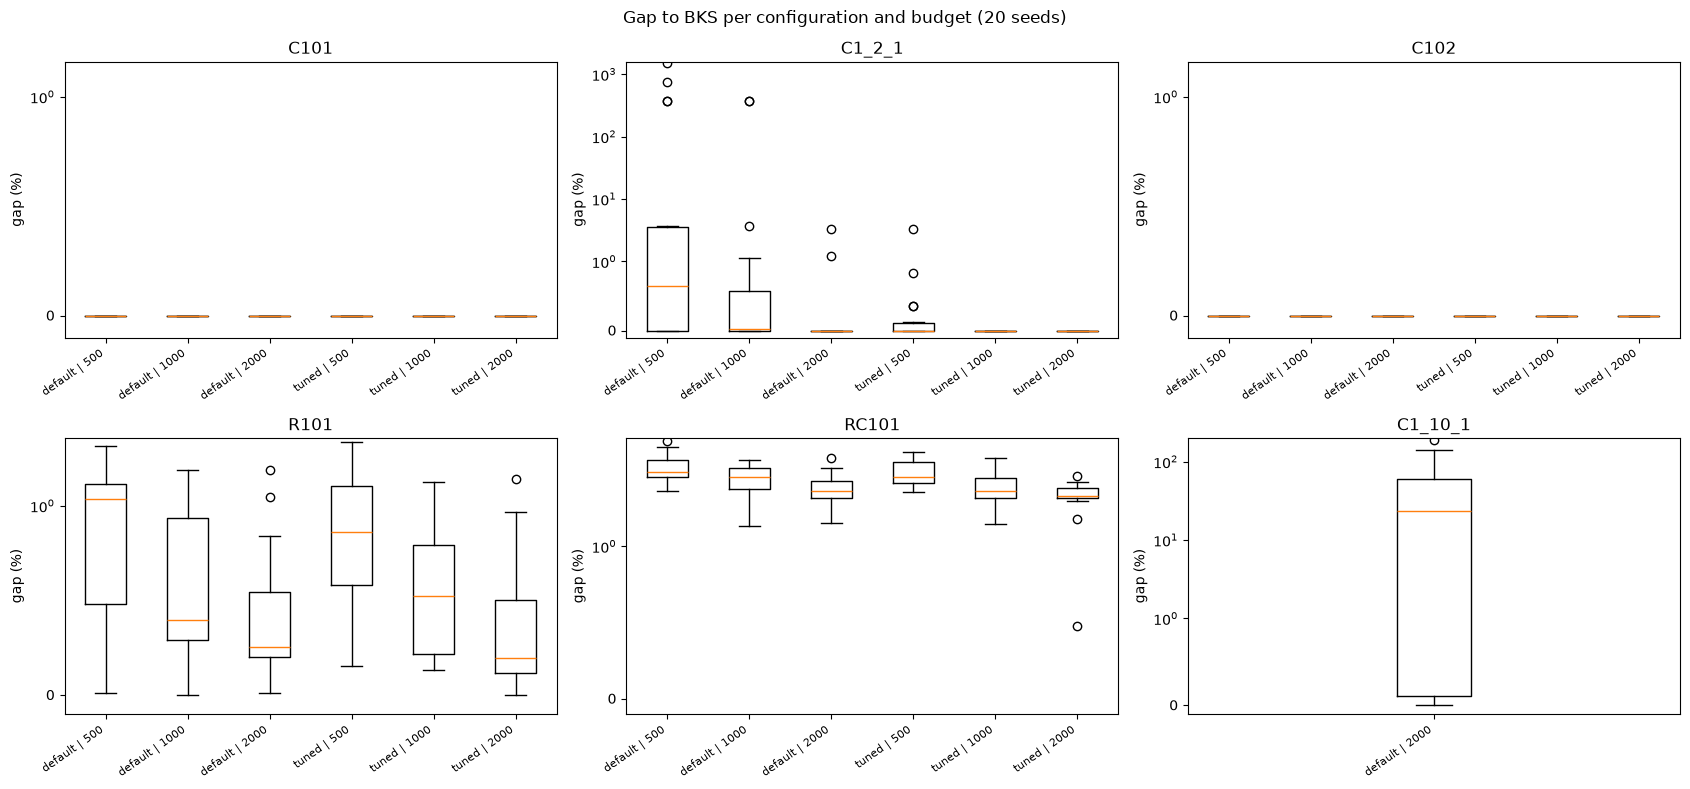

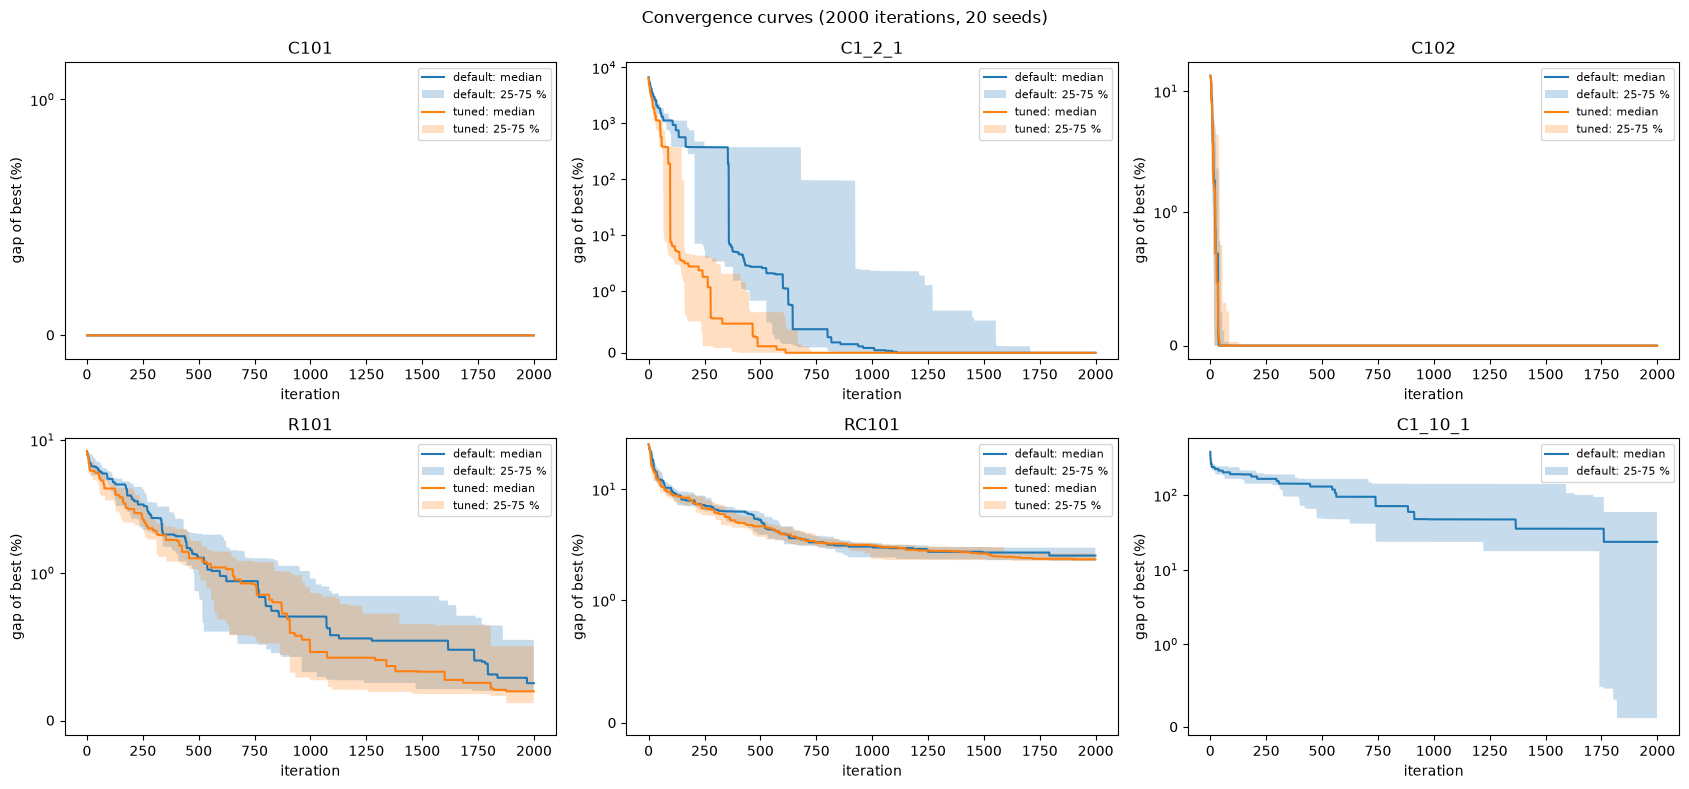

In [15]:
# Gap distribution per configuration and budget (boxplots), and convergence of the best solution (2000 iterations)
names = list(bench.instance.unique())
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, name in zip(axes.flat, names):
    g = bench[bench.instance == name]
    labels = [f"{c} | {b}" for c in CONFIGS for b in BUDGETS if f"{c} | {b}" in set(g.variant)]
    ax.boxplot([g[g.variant == v].gap.round(6).clip(lower=0) for v in labels])   # round: float noise around 0
    ax.set_xticks(range(1, len(labels) + 1), labels, rotation=35, ha="right", fontsize=8)
    ax.set_yscale("symlog", linthresh=1)                    # infeasible runs have gaps of hundreds of %
    ax.set_ylim(-0.1, max(1.5, ax.get_ylim()[1])); ax.set_title(name); ax.set_ylabel("gap (%)")
plt.suptitle("Gap to BKS per configuration and budget (20 seeds)"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, name in zip(axes.flat, names):
    for c in CONFIGS:
        idx = bench.index[(bench.instance == name) & (bench.config == c) & (bench.budget == 2000)]
        if len(idx) == 0:
            continue
        G = np.clip((100 * (np.array([bench_hist[i]["best"] for i in idx]) - BKS[name]) / BKS[name]).round(6), 0, None)
        ax.plot(np.median(G, axis=0), label=f"{c}: median")
        ax.fill_between(range(G.shape[1]), np.percentile(G, 25, axis=0), np.percentile(G, 75, axis=0), alpha=.25,
                        label=f"{c}: 25-75 %")
    ax.set_yscale("symlog", linthresh=1); ax.set_ylim(-0.1, max(1.5, ax.get_ylim()[1]))
    ax.set_title(name); ax.set_xlabel("iteration"); ax.set_ylabel("gap of best (%)")
    ax.legend(fontsize=8)
plt.suptitle("Convergence curves (2000 iterations, 20 seeds)"); plt.tight_layout(); plt.show()

In [16]:
# Default vs tuned: same number of iterations, and roughly the same time (tuned costs about 2x more per iteration)
rows = []
for name, g in bench[bench.instance != "C1_10_1"].groupby("instance", sort=False):
    pairs = [(f"tuned {b} vs default {b}", f"tuned | {b}", f"default | {b}") for b in BUDGETS]
    pairs += [("tuned 1000 vs default 2000 (~ same time)", "tuned | 1000", "default | 2000")]
    for label, vx, vy in pairs:
        x, y = g[g.variant == vx].sort_values("seed"), g[g.variant == vy].sort_values("seed")
        rows.append(dict(instance=name, comparison=label, mean_gap_tuned=x.gap.mean(), mean_gap_default=y.gap.mean(),
                         feasible_tuned=100 * x.feasible.mean(), feasible_default=100 * y.feasible.mean(),
                         time_ratio=x.runtime.mean() / y.runtime.mean(), A12=a12(x.gap, y.gap),
                         p_wilcoxon=wilcoxon_p(x.gap, y.gap)))
fair = pd.DataFrame(rows)
fair["p_holm"] = holm(fair.p_wilcoxon)
fair.round(4)

,instance,comparison,mean_gap_tuned,mean_gap_default,feasible_tuned,feasible_default,time_ratio,A12,p_wilcoxon,p_holm
0,C101,tuned 500 vs default 500,0.0000,0.0000,100.0,100.0,1.1489,0.5000,1.0000,1.0000
1,C101,tuned 1000 vs default 1000,0.0000,0.0000,100.0,100.0,1.1326,0.5000,1.0000,1.0000
2,C101,tuned 2000 vs default 2000,0.0000,0.0000,100.0,100.0,1.1390,0.5000,1.0000,1.0000
3,C101,tuned 1000 vs default 2000 (~ same time),0.0000,0.0000,100.0,100.0,0.5673,0.5000,1.0000,1.0000
4,C1_2_1,tuned 500 vs default 500,0.2598,149.8546,100.0,80.0,1.6513,0.2600,0.0032,0.0640
5,C1_2_1,tuned 1000 vs default 1000,-0.0001,37.4868,100.0,90.0,1.7289,0.2500,0.0051,0.0962
6,C1_2_1,tuned 2000 vs default 2000,-0.0001,0.2283,100.0,100.0,1.7254,0.4500,0.1797,1.0000
7,C1_2_1,tuned 1000 vs default 2000 (~ same time),-0.0001,0.2283,100.0,100.0,0.9033,0.4500,0.1797,1.0000
8,C102,tuned 500 vs default 500,-0.0004,-0.0004,100.0,100.0,1.1233,0.5000,1.0000,1.0000
9,C102,tuned 1000 vs default 1000,-0.0004,-0.0004,100.0,100.0,1.1758,0.5000,1.0000,1.0000


### Analysis of B

**Quality (2000 iterations).**
- C101 and C102 are solved to the BKS in 100 % of the runs, by both configurations. C1_2_1 too, except two default runs that end 1.2 % and 3.4 % above (mean gap 0.23 %, median 0).
- **R101** (random customers, narrow windows of 10 time units): mean gap 0.43 % (default) and 0.35 % (tuned), best run 0.01 % and 0.00 %; the BKS (1642.88, distance-optimal solution with 20 routes) is reached once.
- **RC101** is the hardest 100-customer instance: mean gap 2.6 % (default) and 2.4 % (tuned), best 0.48 %. The ALNS uses 16.1 to 16.2 vehicles where the reference uses 15. Our objective only minimises distance, so it has no incentive to merge a route.
- **The project targets are met** on every instance with a target (mean gap < 7 % for the 100-customer instances). Running times in the table come from parallel runs and are about 2.5 times larger than on an idle machine (see S).

**C1_10_1 (1000 customers).** Only 7 of 20 runs (35 %) are feasible after 2000 iterations. The feasible ones are very close to the BKS (mean gap 0.09 %, best 0.007 %), but the 13 others still leave 1 to 8 customers unserved (initial solution: 16). This is why the mean gap is 48 %: it is dominated by the penalty, and the median (24 %) is one unserved customer. 2000 iterations are too few to remove the last unserved customers when $q$ is capped at 40 (4 % of $n$). This is the same mechanism as $q \in [5, 15]\,\%$ on C1_2_1 in T.

**Tuned vs default.**
- At equal iterations, the tuned configuration is better on C1_2_1 at 500 and 1000 iterations (100 % feasible against 80 % and 90 %, Wilcoxon $p = 0.003$ and $0.005$, $A_{12} = 0.26$ and $0.25$). After Holm correction over the 20 comparisons, these are no longer significant at 5 % ($p_{Holm} = 0.06$ and $0.10$). On R101 and RC101, tuned has a slightly lower mean gap at every budget, but no difference is significant.
- **At equal time** (tuned 1000 iterations vs default 2000, time ratio about 0.57 to 0.90), no difference is significant either. So the tuned $q$ mostly buys speed of convergence on the instances where the initial solution is infeasible (convergence curves of C1_2_1), not a better final quality.
- **Budget.** On R101 and RC101 the gap keeps decreasing from 500 to 2000 iterations (R101: 1.0 → 0.66 → 0.43 %), and the median last improvement is at iteration ~1100 to 1500. The ALNS has not converged at 2000 iterations on these instances; a larger budget would still help.

## Experiment A1: ablation of the operators (RQ3)

**Design.** On the test instances C102 (clustered), R101 (random) and RC101 (mixed), with the default configuration, 2000 iterations and 20 seeds:
1. full ALNS (the "default | 2000" runs of experiment B, same seeds);
2. full ALNS minus one operator (8 variants);
3. full ALNS with $r = 0$: the weights stay at 1, so selection is uniform;
4. a single pair (LNS without adaptation): the destroy and the repair operator that found the most new best solutions in the full ALNS runs of the instance.

The ablation uses the default configuration, which is the algorithm described in section 2. The tuned configuration costs twice as much per iteration.

**Analysis.** Each variant is compared with full ALNS using a paired Wilcoxon test on the gap and a Fisher test on the feasibility rate, both with Holm correction per instance, and $A_{12}$. A Friedman test compares all variants at once.

In [17]:
A1_FILES = ["C102.100.10.vrptw", "R101.txt", "RC101.txt"]

variants = {"r = 0 (uniform)": {"reaction": 0.0}}
for o in DNAMES:
    variants[f"- {o}"] = {"destroy": [x for x in DNAMES if x != o]}
for o in REPAIR_NAMES:
    variants[f"- {o}"] = {"repair": [x for x in REPAIR_NAMES if x != o]}

jobs = [(f, s, label, dict(kw, iterations=2000), ()) for f in A1_FILES for s in SEEDS for label, kw in variants.items()]
abl, abl_hist = cached("A1_ablation", jobs)

full_idx = bench.index[bench.file.isin(A1_FILES) & (bench.variant == "default | 2000")]
full = bench.loc[full_idx].assign(variant="full")
full_hist = {name: [bench_hist[i] for i in full_idx[(full.instance == name).to_numpy()]] for name in full.instance.unique()}

# Single best pair, chosen from the new bests of the full ALNS runs of each instance
best_pair = {}
for f in A1_FILES:
    hs = full_hist[get_instance(f)["label"]]
    best_pair[f] = (max(DNAMES, key=lambda o: sum(h["newbestD"][o] for h in hs)),
                    max(REPAIR_NAMES, key=lambda o: sum(h["newbestR"][o] for h in hs)))
print("Best pair per instance:", best_pair)
jobs = [(f, s, "best pair only", dict(destroy=[d], repair=[r], iterations=2000), ())
        for f, (d, r) in best_pair.items() for s in SEEDS]
pair, _ = cached("A1_best_pair", jobs)

a1_all = pd.concat([full, abl, pair], ignore_index=True)
for name, g in a1_all.groupby("instance", sort=False):
    groups = [gv.sort_values("seed").gap.to_numpy() for _, gv in g.groupby("variant", sort=False)]
    print(f"{name}: Friedman test over the {len(groups)} variants, p = {friedman_p(groups):.3g}")

a1_table = compare(a1_all, ref="full")
a1_table[["instance", "variant", "mean_gap", "median_gap", "std_gap", "ci95_low", "ci95_high", "best_gap", "feasible_pct",
          "A12", "p_wilcoxon", "p_wilcoxon_holm", "p_fisher_holm", "time_s"]].round(3)

Best pair per instance: {'C102.100.10.vrptw': ('worst_removal', 'regret2_repair'), 'R101.txt': ('worst_removal', 'regret2_repair'), 'RC101.txt': ('random_removal', 'regret2_repair')}
C102: Friedman test over the 11 variants, p = 0.119
R101: Friedman test over the 11 variants, p = 5.05e-05
RC101: Friedman test over the 11 variants, p = 0.229


,instance,variant,mean_gap,median_gap,std_gap,ci95_low,ci95_high,best_gap,feasible_pct,A12,p_wilcoxon,p_wilcoxon_holm,p_fisher_holm,time_s
0,C102,full,-0.000,-0.000,0.000,-0.000,-0.000,-0.000,100.0,0.500,NaN,NaN,NaN,36.203
1,C102,r = 0 (uniform),-0.000,-0.000,0.000,-0.000,-0.000,-0.000,100.0,0.500,1.000,1.000,1.0,35.830
2,C102,- random_removal,-0.000,-0.000,0.000,-0.000,-0.000,-0.000,100.0,0.500,1.000,1.000,1.0,36.107
3,C102,- worst_removal,-0.000,-0.000,0.000,-0.000,-0.000,-0.000,100.0,0.500,1.000,1.000,1.0,32.942
4,C102,- shaw_removal,0.511,-0.000,2.285,-0.559,1.580,-0.000,100.0,0.525,0.317,1.000,1.0,35.445
5,C102,- route_removal,-0.000,-0.000,0.000,-0.000,-0.000,-0.000,100.0,0.500,1.000,1.000,1.0,43.068
6,C102,- greedy_repair,-0.000,-0.000,0.000,-0.000,-0.000,-0.000,100.0,0.500,1.000,1.000,1.0,37.263
7,C102,- greedy_noise_repair,-0.000,-0.000,0.000,-0.000,-0.000,-0.000,100.0,0.500,1.000,1.000,1.0,36.753
8,C102,- regret2_repair,-0.000,-0.000,0.000,-0.000,-0.000,-0.000,100.0,0.500,1.000,1.000,1.0,36.475
9,C102,- regret3_repair,-0.000,-0.000,0.000,-0.000,-0.000,-0.000,100.0,0.500,1.000,1.000,1.0,36.454


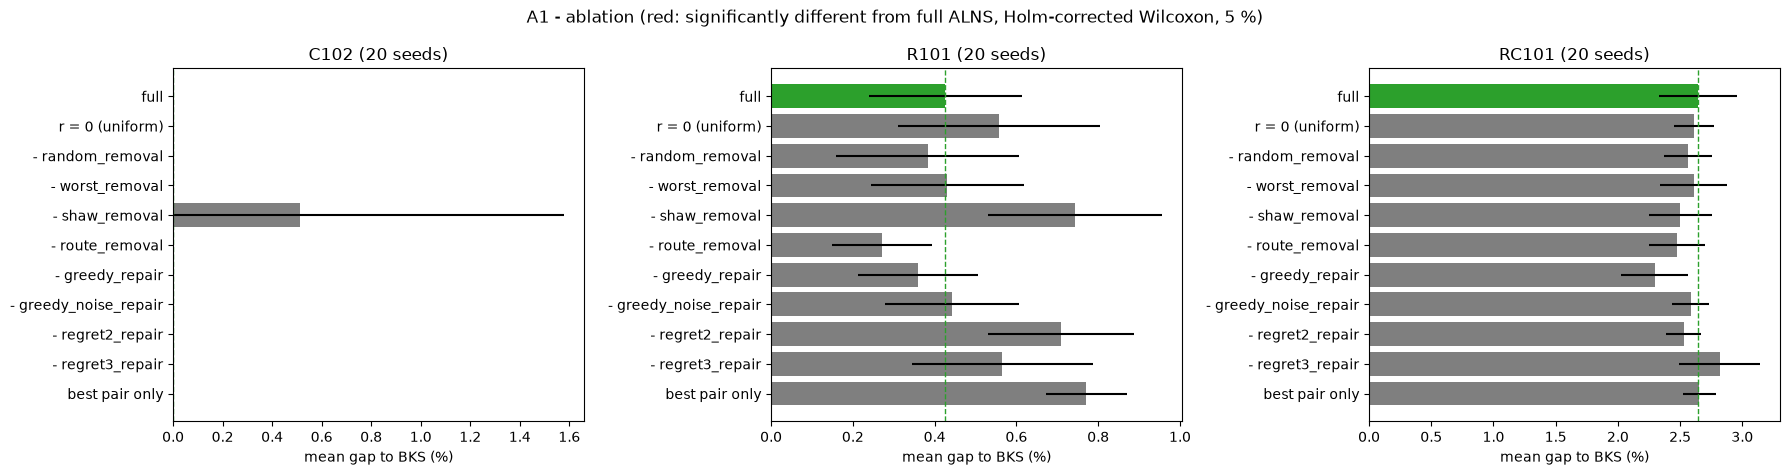

In [18]:
# Mean gap with 95 % confidence interval per variant (one panel per instance)
fig, axes = plt.subplots(1, len(A1_FILES), figsize=(6 * len(A1_FILES), 4.8))
for ax, (name, t) in zip(axes, a1_table.groupby("instance", sort=False)):
    mean_gap = t.mean_gap.clip(lower=0)                     # gaps of -0.0003 % come from the BKS rounded to 2 decimals
    err = np.vstack([mean_gap - t.ci95_low.clip(lower=0), t.ci95_high.clip(lower=0) - mean_gap])
    colors = ["tab:green" if v == "full" else ("tab:red" if p < 0.05 else "tab:gray")
              for v, p in zip(t.variant, t.p_wilcoxon_holm.fillna(1))]
    ax.barh(t.variant, mean_gap, xerr=err, color=colors)
    ax.axvline(mean_gap[t.variant == "full"].iloc[0], color="tab:green", ls="--", lw=1)
    ax.invert_yaxis(); ax.set_title(f"{name} (20 seeds)"); ax.set_xlabel("mean gap to BKS (%)")
fig.suptitle("A1 - ablation (red: significantly different from full ALNS, Holm-corrected Wilcoxon, 5 %)")
plt.tight_layout(); plt.show()

### Analysis of A1

- **No component is indispensable.** After Holm correction, no variant is significantly different from the full ALNS on any of the three test instances (all $p_{Holm} \ge 0.07$, no red bar). The Friedman test is significant only on R101 ($p = 5 \times 10^{-5}$), not on C102 ($p = 0.12$) nor RC101 ($p = 0.23$).
- **R101 shows the useful operators.** The variants that degrade the gap the most are: without Shaw removal (0.74 % vs 0.43 %, raw $p = 0.027$), without regret-2 (0.71 %, raw $p = 0.046$), and "best pair only" (worst removal + regret-2: 0.77 %, raw $p = 0.007$, $p_{Holm} = 0.07$). Using only the best pair is worse than using the full portfolio: the other operators bring diversification. On the other hand, removing route removal or greedy repair gives slightly better means (0.27 % and 0.36 %), without significance: these operators mostly waste iterations on R101.
- **C102** is solved in every variant except one run without Shaw removal, which confirms that Shaw removal (relatedness) matters on clustered instances.
- **Adaptive weights.** The uniform selection ($r = 0$) is not significantly different from the adaptive one on any instance (R101: 0.56 % vs 0.43 %, $p_{Holm} = 1$). With 20 segments and $r = 0.1$, the weights have little time to move (see A2), so the adaptive layer brings little in 2000 iterations.

## Experiment A2: operator usage and weight dynamics (RQ4)

**Design.** We reuse the full ALNS runs of A1 on one clustered (C102), one random (R101) and one mixed (RC101) instance. The weights are logged at the end of every segment (100 iterations). Selection probability $= w_o / \sum w$, averaged over the 20 seeds.

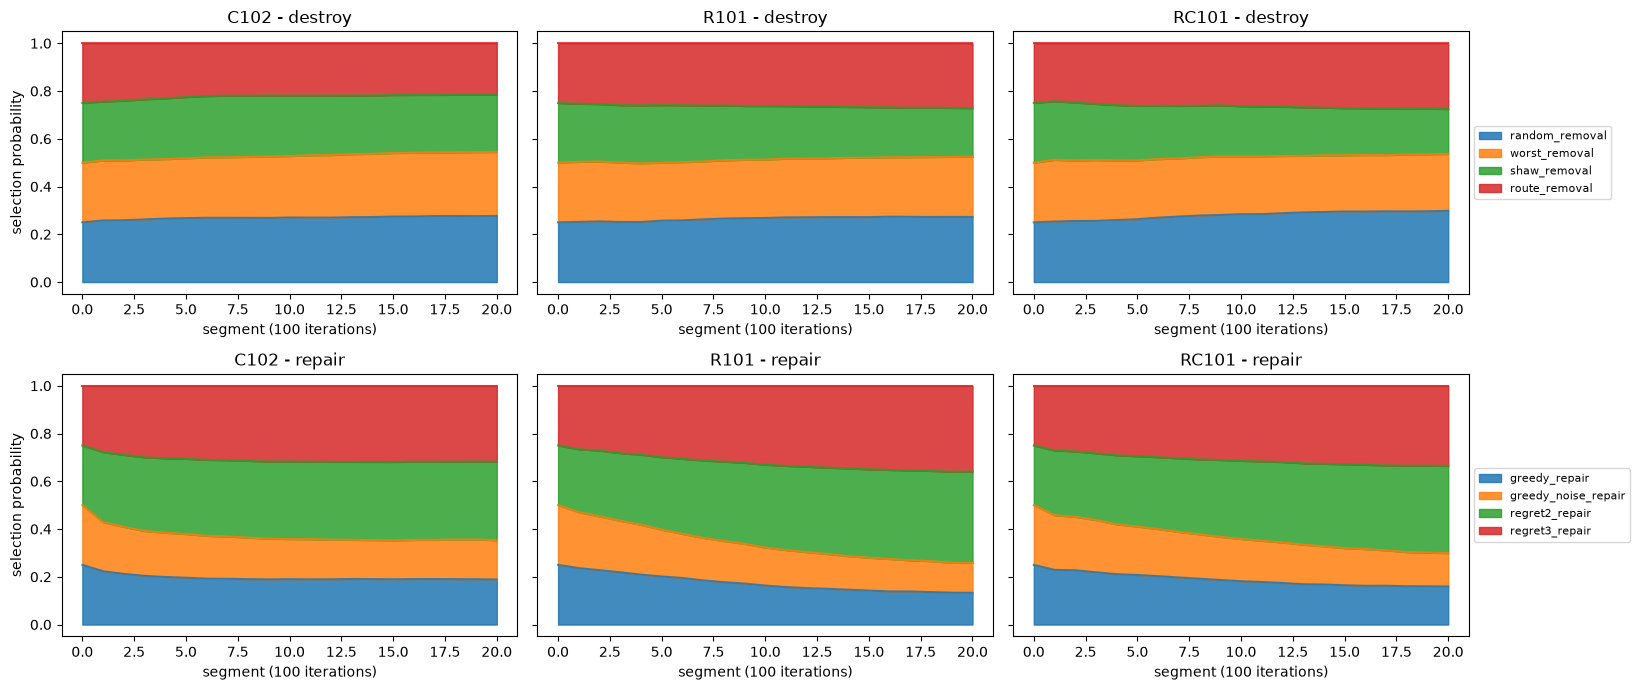

In [19]:
names = list(full_hist)
fig, axes = plt.subplots(2, len(names), figsize=(5.5 * len(names), 7), sharey=True)
for c, name in enumerate(names):
    for row, key in enumerate(("wD", "wR")):
        probs = [pd.DataFrame(h[key]).pipe(lambda W: W.div(W.sum(axis=1), axis=0)) for h in full_hist[name]]
        P = sum(probs) / len(probs)                         # selection probability, averaged over the seeds
        P.plot.area(ax=axes[row, c], alpha=.85, legend=False)
        axes[row, c].set_title(f"{name} - {'destroy' if key == 'wD' else 'repair'}")
        axes[row, c].set_xlabel("segment (100 iterations)"); axes[row, c].set_ylabel("selection probability")
        if c == len(names) - 1:
            axes[row, c].legend(*axes[row, c].get_legend_handles_labels(), loc="center left", bbox_to_anchor=(1, .5), fontsize=8)
plt.tight_layout(); plt.show()

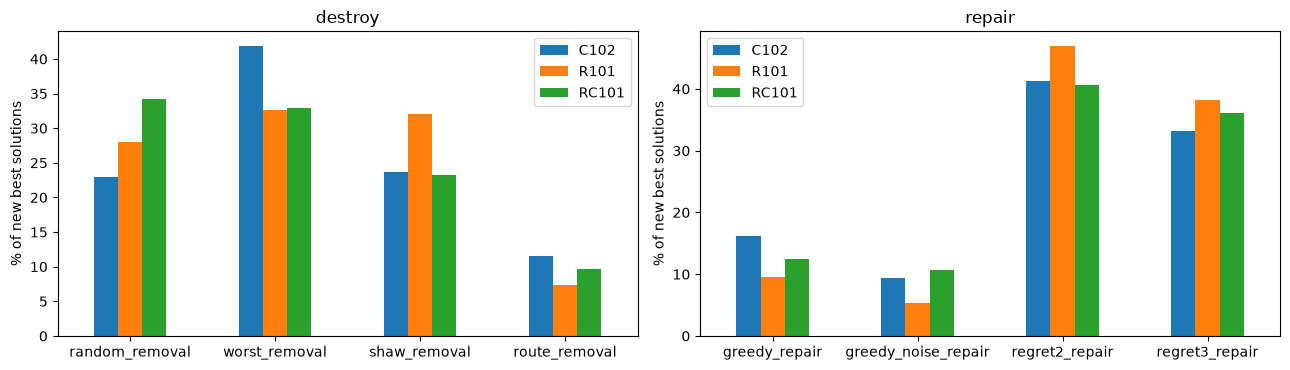

C102  R101  RC101
newbestD random_removal       23.0  28.0   34.2
         worst_removal        41.9  32.6   32.9
         shaw_removal         23.6  32.0   23.2
         route_removal        11.5   7.4    9.7
newbestR greedy_repair        16.2   9.5   12.5
         greedy_noise_repair   9.5   5.3   10.7
         regret2_repair       41.2  47.0   40.6
         regret3_repair       33.1  38.3   36.1

In [20]:
# Share of the new best solutions found by each operator (full ALNS runs)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
shares = {}
for ax, key, ops in ((axes[0], "newbestD", DNAMES), (axes[1], "newbestR", REPAIR_NAMES)):
    share = pd.DataFrame({name: {o: sum(h[key][o] for h in full_hist[name]) for o in ops} for name in names})
    shares[key] = 100 * share / share.sum()
    shares[key].plot.bar(ax=ax, rot=0)
    ax.set_ylabel("% of new best solutions"); ax.set_title("destroy" if key == "newbestD" else "repair")
plt.tight_layout(); plt.show()
pd.concat(shares).round(1)

### Analysis of A2

- **Destroy operators:** the selection probabilities stay close to uniform (0.25 each) during the whole run; route removal decreases slightly (to about 0.22 to 0.27). This confirms A1: the adaptive layer hardly changes the destroy mix.
- **Repair operators:** the weights do move. The two regret repairs gain probability (regret-2 and regret-3 together go from 0.50 to about 0.65 to 0.75), mostly on R101 and RC101, and greedy with noise drops to about 0.12 to 0.16. This matches the share of new best solutions: **regret-2 and regret-3 find 74 to 85 % of the new best solutions**, greedy repairs only 15 to 26 %.
- On the destroy side, the new best solutions are spread between random, worst and Shaw removal (23 to 42 % each), and route removal finds only 7 to 12 % of them, which is consistent with A1 (removing it does not hurt).

## Experiment C: cost of the time windows and of the limited fleet (RQ5)

**Design.** On the four 100-customer instances, we compare the ALNS on the original problem with the ALNS on two relaxed problems, removing one constraint at a time:
- **no time windows**: every window is opened to $[0, +\infty)$, which turns the problem into a CVRP;
- **unlimited fleet**: as many vehicles as customers.

Default configuration, 2000 iterations, 20 seeds; the original runs are the "default | 2000" runs of B. The cost of a constraint is the extra distance it causes: $\Delta = d_{\text{original}} - d_{\text{relaxed}}$, measured on the mean and on the best of the 20 runs. Both problems are solved heuristically, so $\Delta$ is an estimate.

In [21]:
C_FILES = ["C101.txt", "C102.100.10.vrptw", "R101.txt", "RC101.txt"]
RELAX = ["no time windows", "unlimited fleet"]
jobs = [(f, s, r, dict(relax=r, iterations=2000), ()) for f in C_FILES for s in SEEDS for r in RELAX]
cons, _ = cached("C_constraints", jobs)
base = bench[bench.file.isin(C_FILES) & (bench.variant == "default | 2000")].assign(variant="original")
cc = pd.concat([base, cons], ignore_index=True)

rows = []
for name, g in cc.groupby("instance", sort=False):
    o = g[g.variant == "original"].sort_values("seed")
    for r in RELAX:
        x = g[g.variant == r].sort_values("seed")
        rows.append(dict(instance=name, constraint=r.replace("no ", "").replace("unlimited fleet", "fleet limit"),
                         mean_dist_original=o.dist.mean(), mean_dist_relaxed=x.dist.mean(),
                         best_dist_original=o.dist.min(), best_dist_relaxed=x.dist.min(),
                         vehicles_original=o.vehicles.mean(), vehicles_relaxed=x.vehicles.mean(),
                         cost_mean_pct=100 * (o.dist.mean() - x.dist.mean()) / x.dist.mean(),
                         cost_best_pct=100 * (o.dist.min() - x.dist.min()) / x.dist.min(),
                         p_wilcoxon=wilcoxon_p(o.dist, x.dist), feasible_relaxed=100 * x.feasible.mean()))
constraint_cost = pd.DataFrame(rows)
constraint_cost["p_holm"] = holm(constraint_cost.p_wilcoxon)
constraint_cost.round(3)

,instance,constraint,mean_dist_original,mean_dist_relaxed,best_dist_original,best_dist_relaxed,vehicles_original,vehicles_relaxed,cost_mean_pct,cost_best_pct,p_wilcoxon,feasible_relaxed,p_holm
0,C101,time windows,828.937,826.803,828.937,819.558,10.00,10.00,0.258,1.144,0.080,100.0,0.48
1,C101,fleet limit,828.937,828.937,828.937,828.937,10.00,10.00,0.000,0.000,1.000,100.0,1.00
2,C102,time windows,828.937,828.483,828.937,819.558,10.00,10.00,0.055,1.144,0.563,100.0,1.00
3,C102,fleet limit,828.937,828.937,828.937,828.937,10.00,10.00,-0.000,0.000,1.000,100.0,1.00
4,R101,time windows,1649.881,835.123,1643.089,829.465,19.85,8.00,97.561,98.090,0.000,100.0,0.00
5,R101,fleet limit,1649.881,1649.881,1643.089,1643.089,19.85,19.85,0.000,0.000,1.000,100.0,1.00
6,RC101,time windows,1666.448,983.312,1647.532,977.447,16.20,9.00,69.473,68.555,0.000,100.0,0.00
7,RC101,fleet limit,1666.448,1666.448,1647.532,1647.532,16.20,16.20,0.000,0.000,1.000,100.0,1.00


### Analysis of C

- **Time windows are the expensive constraint on R101 and RC101.** Without them, the mean distance drops from 1650 to 835 on R101 (the time windows cost **+98 %** of distance) and from 1666 to 983 on RC101 (**+69 %**), with 8 and 9 vehicles instead of 20 and 16 (Wilcoxon, $p_{Holm} < 0.001$). With windows of 10 to 30 time units on a horizon of 230 to 240, a vehicle can only serve a few customers in a row.
- **On the clustered instances C101 and C102, the time windows cost almost nothing** (+0.26 % and +0.06 % on the mean, +1.1 % on the best run; not significant). The customers of a cluster have compatible windows, so the routes that respect the windows are also short routes.
- **The fleet limit costs nothing on these four instances**: the runs with an unlimited fleet are identical to the original runs (same seeds, same solutions). The ALNS uses 10 to 20 vehicles out of 25 available, so the constraint is never active. It would only matter on instances where the fleet is tight (C1_2_1 and C1_10_1, demand / capacity ≈ 0.9), where its cost is the infeasible runs we observed in T and B.
- Both problems are solved heuristically, so these costs are estimates: on R101 and RC101 the relaxed CVRP is easier for the ALNS, which slightly overestimates the cost of the windows.

## CO$_2$ impact

**Emission factor.** We assume that one distance unit is 1 km and that the routes are driven by 19 t rigid diesel trucks. We use **EF = 0.84 kg CO$_2$e per km**, the value for a 19 t rigid truck computed from the ADEME *Base Empreinte* factor for road diesel (as published by Celsius, *Émissions CO2 d'un camion*, projetcelsius.com). The ADEME factor for diesel itself is about 3.1 kg CO$_2$e per litre. A different vehicle only scales every value by the same factor (for example about 0.5 kg/km for a light commercial vehicle).

**Measures.** Emissions of one execution of the routes, $\text{CO}_2 = \text{EF} \times d$. We report them for the construction heuristic (initial regret-2 solution), the default and tuned ALNS (mean over 20 runs, 2000 iterations) and the BKS. We also report the cost of each constraint from experiment C, and a yearly figure assuming the same routes are driven 250 days a year.

In [22]:
EF = 0.84          # kg CO2e per km (19 t rigid diesel truck, ADEME Base Empreinte); assumption: 1 distance unit = 1 km
DAYS = 250         # working days per year, for the yearly figures

rows = []
for name, g in bench[bench.budget == 2000].groupby("instance", sort=False):
    init = g[g.initial_unassigned == 0].initial_dist      # the construction is only comparable when it serves everyone
    row = dict(instance=name, construction_kg=EF * init.mean() if len(init) else np.nan)
    for c in CONFIGS:
        gc = g[(g.config == c) & g.feasible]
        row[f"alns_{c}_kg"] = EF * gc.dist.mean() if len(gc) else np.nan
    row["BKS_kg"] = EF * BKS[name]
    best_alns = pd.Series([row[f"alns_{c}_kg"] for c in CONFIGS]).min()   # nan if no feasible run
    row["saving_vs_construction_pct"] = 100 * (1 - best_alns / row["construction_kg"])
    row["saving_vs_construction_t_per_year"] = (row["construction_kg"] - best_alns) * DAYS / 1000
    row["excess_vs_BKS_pct"] = 100 * (best_alns / row["BKS_kg"] - 1)
    rows.append(row)
co2 = pd.DataFrame(rows)
display(co2.round(2))

co2_constraints = constraint_cost[["instance", "constraint"]].assign(
    extra_kg_per_day=EF * (constraint_cost.mean_dist_original - constraint_cost.mean_dist_relaxed),
    extra_t_per_year=EF * (constraint_cost.mean_dist_original - constraint_cost.mean_dist_relaxed) * DAYS / 1000)
co2_constraints.round(2)

,instance,construction_kg,alns_default_kg,alns_tuned_kg,BKS_kg,saving_vs_construction_pct,saving_vs_construction_t_per_year,excess_vs_BKS_pct
0,C101,696.31,696.31,696.31,696.31,-0.00,-0.00,0.00
1,C1_2_1,NaN,2277.03,2271.84,2271.84,NaN,NaN,-0.00
2,C102,790.15,696.31,696.31,696.31,11.88,23.46,-0.00
3,R101,1493.73,1385.90,1384.86,1380.02,7.29,27.22,0.35
4,RC101,1710.32,1399.82,1395.87,1363.79,18.39,78.61,2.35
5,C1_10_1,NaN,35715.42,NaN,35682.32,NaN,NaN,0.09


,instance,constraint,extra_kg_per_day,extra_t_per_year
0,C101,time windows,1.79,0.45
1,C101,fleet limit,0.00,0.00
2,C102,time windows,0.38,0.10
3,C102,fleet limit,-0.00,-0.00
4,R101,time windows,684.40,171.10
5,R101,fleet limit,0.00,0.00
6,RC101,time windows,573.83,143.46
7,RC101,fleet limit,0.00,0.00


### Analysis of the CO$_2$ impact

- **Optimisation vs construction.** On the instances where the regret-2 construction serves every customer, the ALNS reduces the emissions by **11.9 % on C102, 7.3 % on R101 and 18.4 % on RC101**, i.e. 23 to 79 t CO$_2$e per year for a single daily tour (on C101 the construction is already optimal). On C1_2_1 and C1_10_1 the construction leaves customers unserved, so it cannot be compared.
- **Remaining margin.** The ALNS routes are 0 to 2.4 % above the BKS: improving the algorithm further would save at most 0.03 t per day on RC101. The gain from optimising at all is much larger than the gain from optimising better.
- **Constraints.** The time windows of R101 and RC101 cost 574 to 684 kg CO$_2$e per day (143 to 171 t per year) compared with free delivery times. This quantifies the environmental cost of narrow delivery slots, while it is almost zero on the clustered instances.
- These figures scale linearly with the emission factor and assume that a distance unit is 1 km and that the routes are driven every working day.

## Experiment S: time per iteration vs $n$ (RQ6)

**Design.** 100 iterations, 3 seeds, on five clustered instances from 25 to 1000 customers. We measure full ALNS (default configuration) and ALNS restricted to each repair operator, excluding the time of the initial solution. This experiment was run alone on the machine, so its times are not inflated by parallel runs.

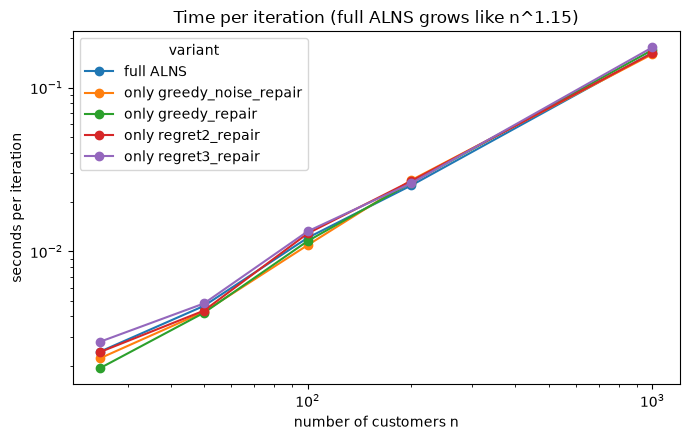

,initial solution (s)
n,
25,0.02
50,0.06
100,0.23
200,0.73
1000,22.02


variant,full ALNS,only greedy_noise_repair,only greedy_repair,only regret2_repair,only regret3_repair
n,,,,,
25,0.0024,0.0022,0.0019,0.0024,0.0028
50,0.0046,0.0043,0.0042,0.0043,0.0048
100,0.0121,0.0109,0.0116,0.0129,0.0132
200,0.0253,0.0272,0.0263,0.0269,0.0261
1000,0.1632,0.1599,0.1697,0.1623,0.1760


In [23]:
SIZE_FILES = ["C101.25.3.vrptw", "C101.50.5.vrptw", "C101.txt", "C1_2_1.200.20.vrptw", "C1_10_1.1000.100.vrptw"]
size_variants = {"full ALNS": {}, **{f"only {o}": {"repair": [o]} for o in REPAIR_NAMES}}
jobs = [(f, s, label, dict(kw, iterations=100), ()) for f in SIZE_FILES for s in range(3)
        for label, kw in size_variants.items()]
sz, _ = cached("S_time_per_iteration", jobs)

Tn = sz.groupby(["variant", "n"]).iter_time.mean().unstack(0)
ax = Tn.plot(marker="o", logx=True, logy=True, figsize=(7, 4.5))
ax.set_xlabel("number of customers n"); ax.set_ylabel("seconds per iteration")
slope = np.polyfit(np.log(Tn.index), np.log(Tn["full ALNS"]), 1)[0]
ax.set_title(f"Time per iteration (full ALNS grows like n^{slope:.2f})")
plt.tight_layout(); plt.show()
init_time = (sz.runtime - sz.iter_time * sz.iterations).groupby(sz.n).mean()
display(pd.DataFrame({"initial solution (s)": init_time}).round(2))
Tn.round(4)

### Analysis of S

- The time per iteration grows like $n^{1.15}$ (log-log fit over 25 to 1000 customers): 2.4 ms at $n = 25$, 12 ms at $n = 100$, 0.16 s at $n = 1000$. The cost of one iteration is dominated by the repair (insertion of $q$ customers with feasibility checks of the time windows); because $q$ is capped at 40 in the default configuration, it grows less than quadratically. Without the cap, $q$ grows with $n$ and so does the time per iteration (tuned configuration in B: 1.7 times slower on C1_2_1).
- The repair operators have almost the same cost per iteration (within 10 to 20 %); regret-3 is the slowest.
- The initial regret-2 solution is the expensive part at large $n$: 22 s at $n = 1000$ (0.23 s at $n = 100$), i.e. the equivalent of about 135 ALNS iterations.
- **Practical consequence:** 2000 iterations on C1_10_1 take about 6 min on an idle machine, which is not enough to reach feasibility in 65 % of the runs (B). For 1000 customers, the iteration budget should be scaled with $n$, or $q$ should grow with $n$ while unserved customers remain.

## Correctness and raw data

Every final solution of every run is checked by `check_solution`, which is independent of the ALNS code: it checks that each customer is visited once, the fleet size, the capacity of each route and the time windows, and it recomputes the cost from the routes. Below we check that no run violates a constraint (an unserved customer is reported separately as infeasibility, not as a violation), and that the recomputed cost equals the cost computed by the ALNS. The raw results of every run are exported as CSV files in `results/`.

In [24]:
all_runs = pd.concat([tun.assign(experiment="T"), bench.assign(experiment="B"), abl.assign(experiment="A1"),
                      pair.assign(experiment="A1"), cons.assign(experiment="C"), sz.assign(experiment="S")],
                     ignore_index=True)
assert (all_runs.violations == 0).all(), "a final solution violates capacity, time windows or fleet size"
assert (all_runs.cost_mismatch < 1e-6).all(), "recomputed cost differs from the ALNS cost"

for name, df in {"T_q_temperature": tun, "B_benchmark_budgets": bench, "A1_ablation": abl, "A1_best_pair": pair,
                 "C_constraints": cons, "S_time_per_iteration": sz}.items():
    df.to_csv(f"results/{name}.csv", index=False)

all_runs.groupby("experiment", sort=False).agg(runs=("seed", "size"), feasible_pct=("feasible", "mean"),
    violations=("violations", "sum"), max_cost_mismatch=("cost_mismatch", "max")).assign(
    feasible_pct=lambda d: 100 * d.feasible_pct)

,runs,feasible_pct,violations,max_cost_mismatch
experiment,,,,
T,480,97.916667,0,4.092726e-12
B,620,96.935484,0,8.003553e-11
A1,600,100.000000,0,2.273737e-12
C,160,100.000000,0,1.591616e-12
S,75,61.333333,0,3.637979e-11


## Conclusions

| RQ | Answer |
|---|---|
| RQ1 ($q$, $w$) | $q$ is the parameter that matters: $q \ge 10\,\%$ of $n$ always reaches the BKS of C1_2_1, $q \in [5,15]\,\%$ only in 55 % of the runs. $w$ has no significant effect, because $T_0$ is computed on the penalised objective of an infeasible initial solution. |
| RQ2 (quality, budget) | Mean gap 0 % on C101, C102, C1_2_1, 0.35 to 0.43 % on R101, 2.4 to 2.6 % on RC101 (2000 iterations): the targets are met. On C1_10_1 only 35 % of the runs are feasible after 2000 iterations. Tuned and default are not significantly different after Holm correction, at equal iterations or equal time. |
| RQ3 (ablation) | No single operator is indispensable. On R101, Shaw removal and regret-2 are the most useful, and using only the best pair is worse than the full portfolio. Adaptive weights are not better than uniform selection in 2000 iterations. |
| RQ4 (operator usage) | Destroy weights stay almost uniform; regret repairs take 65 to 75 % of the selection and produce 74 to 85 % of the new best solutions. |
| RQ5 (constraints) | Time windows cost +69 to +98 % of distance on R101 / RC101, almost nothing on clustered instances. The fleet limit is never active on the 100-customer instances. |
| RQ6 (scalability) | Time per iteration grows like $n^{1.15}$; the initial solution takes 22 s at $n = 1000$. |

**Limits.**
- Only one algorithm (ALNS) is studied in this notebook, so the comparison between algorithms of the guide (same tuning effort for GRASP, TS, ALNS) does not apply. Within the ALNS, both configurations are compared at equal iterations and at roughly equal time.
- The tuning was done on 2 instances, and C101 turned out to be non-informative (optimal initial solution). A larger tuning set would make the choice of $q$ more robust.
- The objective only minimises distance (with a penalty for unserved customers), not the number of vehicles. The reference solutions of R101 / RC101 have their own objective (distance-optimal solutions computed by exact methods), so this is a fair reference for our objective.
- The running times of T, B, A1 and C come from 11 parallel processes and are about 2.5 times larger than on an idle machine. Only S was timed alone.
- The CO$_2$ factor comes from a secondary source (Celsius, quoting ADEME Base Empreinte) and assumes 1 distance unit = 1 km.

## Checklist status

| Item | Status | Where / justification |
|---|---|---|
| Research questions written before running experiments | Done | RQ1 to RQ6 at the top of the study |
| Instances listed, with features (n, distribution) and tuning/test split | Done | Instance table (n, distribution, fleet, tightness, window width, BKS, role). `C1_2_1.txt` is not used: same instance as `C1_2_1.200.20.vrptw` with 50 vehicles instead of 20 |
| Quality indicator (gap, Eq. 1) and budget defined and justified | Done | Protocol section (gap with the penalty, 2000 iterations as reference budget, 500 / 1000 / 2000 in B) |
| ≥ 20 runs per (instance, configuration), same seeds everywhere | Done | 20 seeds (0 to 19) in T, B, A1, C; 3 seeds only in S, which measures time, not quality |
| Every final solution checked for feasibility and cost recomputed | Done | `check_solution` on every run, assertions in the correctness section (0 violations, cost mismatch < $10^{-10}$) |
| Distances follow the CVRPLIB rounding convention | Justified deviation | These are Solomon / Gehring & Homberger instances: their BKS (SINTEF) use double-precision distances, so we do the same. Integer rounding would make the gaps meaningless |
| Caches / global state reset between runs; runs reproducible from the seed | Done | Assertions: `alns_exp` reproduces `alns`, and the same job run twice gives the same result. Each run uses its own seeded RNG |
| Benchmark table: instance, BKS, best & mean cost, gap, time, #vehicles | Done | Benchmark table of B |
| Mean, median, std, CI reported; boxplots and convergence curves | Done | `describe` (scipy `t.interval` for the CI), boxplots and convergence curves of B |
| Trajectory plots used to explain behaviour | Done | Trajectories and acceptance rate in T (diversification with $w = 20\,\%$ vs descent with $w = 0$) |
| Parameter sensitivity: ALNS (operators, $q$, acceptance) | Done | T ($q$ × $w$), A1 (operators, adaptive weights). GRASP $\alpha$ and TS tenure: not applicable (no GRASP / TS in this project) |
| Ablation of at least one component | Done | A1: each operator removed, uniform weights, best pair only |
| Statistical tests, multiple-comparison correction, effect sizes | Done | scipy: `wilcoxon`, `friedmanchisquare`, `fisher_exact`; statsmodels `multipletests` (Holm); Vargha–Delaney $A_{12}$ |
| Fair comparison (same budget, same tuning effort), several budgets | Partial | Same budgets (500 / 1000 / 2000) and an equal-time comparison. "Same tuning effort" across algorithms does not apply to a single algorithm |
| Scalability study up to ≥ 1000 customers | Done | S (25 to 1000 customers) and C1_10_1 in B |
| Average gap < 5 % / < 7 %, or justification | Done | Met on every 100-customer instance; C1_10_1 (no target) discussed in B |
| Two extra constraints studied (cost of each constraint) | Done | C: time windows and fleet limit |
| CO$_2$ impact quantified with a stated emission factor | Done | 0.84 kg CO$_2$e/km (19 t truck, ADEME via Celsius) |
| Environment table, code version, raw data and analysis scripts delivered | Done | Environment table (versions, git commit), raw CSV of every run in `results/`, all analysis code in this notebook |